<a href="https://colab.research.google.com/github/Taniya-roy20/heart-disease-prediction/blob/main/heart_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_path = "/content/heart+disease (1).zip"
extract_path = "/content/heart_disease_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)

processed.hungarian.data
switzerland.data
hungarian.data
new.data
processed.switzerland.data
heart-disease.names
cleveland.data
Index
reprocessed.hungarian.data
processed.cleveland.data
cleve.mod
long-beach-va.data
bak
ask-detrano
WARNING
processed.va.data
heart-disease.expense
Index
heart-disease.cost
heart-disease.delay
heart-disease.group
heart-disease.README


In [3]:
import pandas as pd
import glob

# Find the Cleveland dataset
files = glob.glob(
    '/content/heart_disease_data/**/processed.cleveland.data',
    recursive=True
)

file_path = files[0]

# Define column names
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

# Load dataset
df = pd.read_csv(
    file_path,
    header=None,
    names=columns,
    na_values='?'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (303, 14)

First Five Records:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [6]:
# Display rows containing missing values

missing_rows = df[df.isnull().any(axis=1)]

print("Rows containing missing values:")
print(missing_rows)

print("\nTotal rows containing missing values:")
print(len(missing_rows))

Rows containing missing values:
      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca  thal  num  
87     1.0  0.0   NaN    0  
166    1.0  NaN   3.0    0  
192    2.0  NaN   7.0    1  
266    2.0  0.0   NaN    2  
287    2.0  NaN   7.0    0  
302    1.0  NaN   3.0    0  

Total rows containing missing values:
6


In [7]:
print("Target variable distribution:")
print(df['num'].value_counts().sort_index())

Target variable distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [8]:
print(df.describe())

              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  241.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  275.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  299.000000   
mean     0.990099  149.607261    0.326733    1.039604    1.600660    0.672241   
std      0.994971   22.8750

In [11]:
print(df.dtypes)

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object


In [12]:
print(df['num'].value_counts().sort_index())

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [13]:
missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:", len(missing_rows))
print(missing_rows)

Number of rows containing missing values: 6
      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca  thal  num  
87     1.0  0.0   NaN    0  
166    1.0  NaN   3.0    0  
192    2.0  NaN   7.0    1  
266    2.0  0.0   NaN    2  
287    2.0  NaN   7.0    0  
302    1.0  NaN   3.0    0  


In [14]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**STEP 2: DATA EXPLORATION AND STATISTICAL ANALYSIS**


1. DATASET DIMENSIONS
Total observations: 303
Total attributes: 14
Dataset shape: (303, 14)

2. DATASET STRUCTURE

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

First five records:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  ex

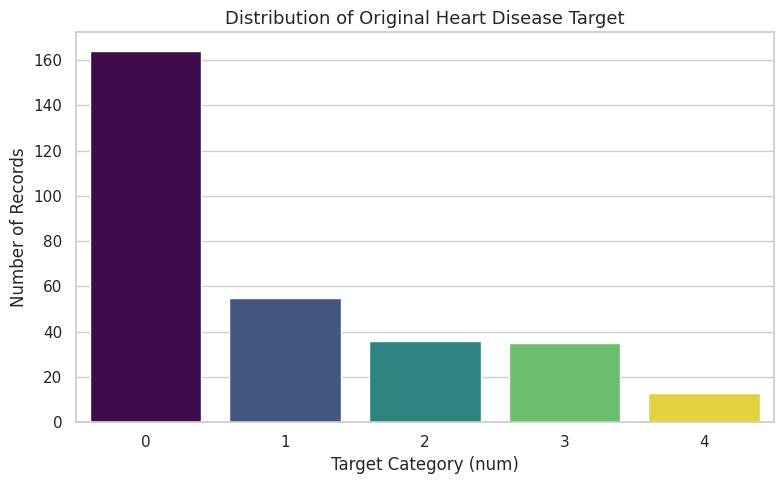

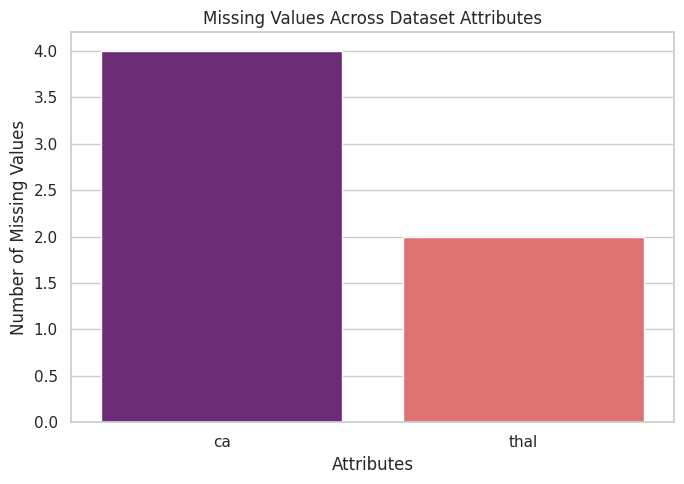

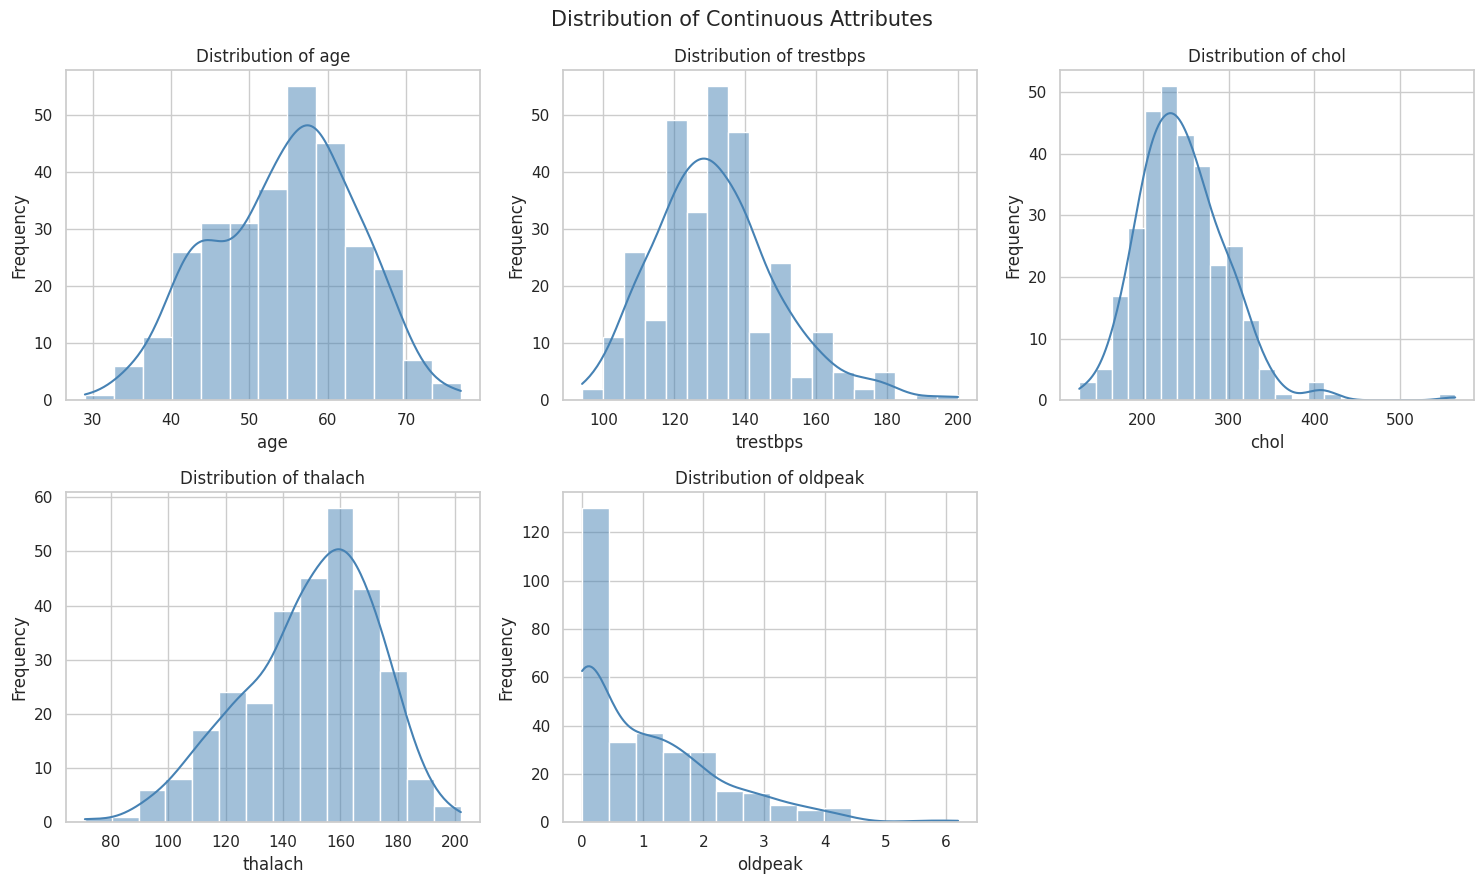

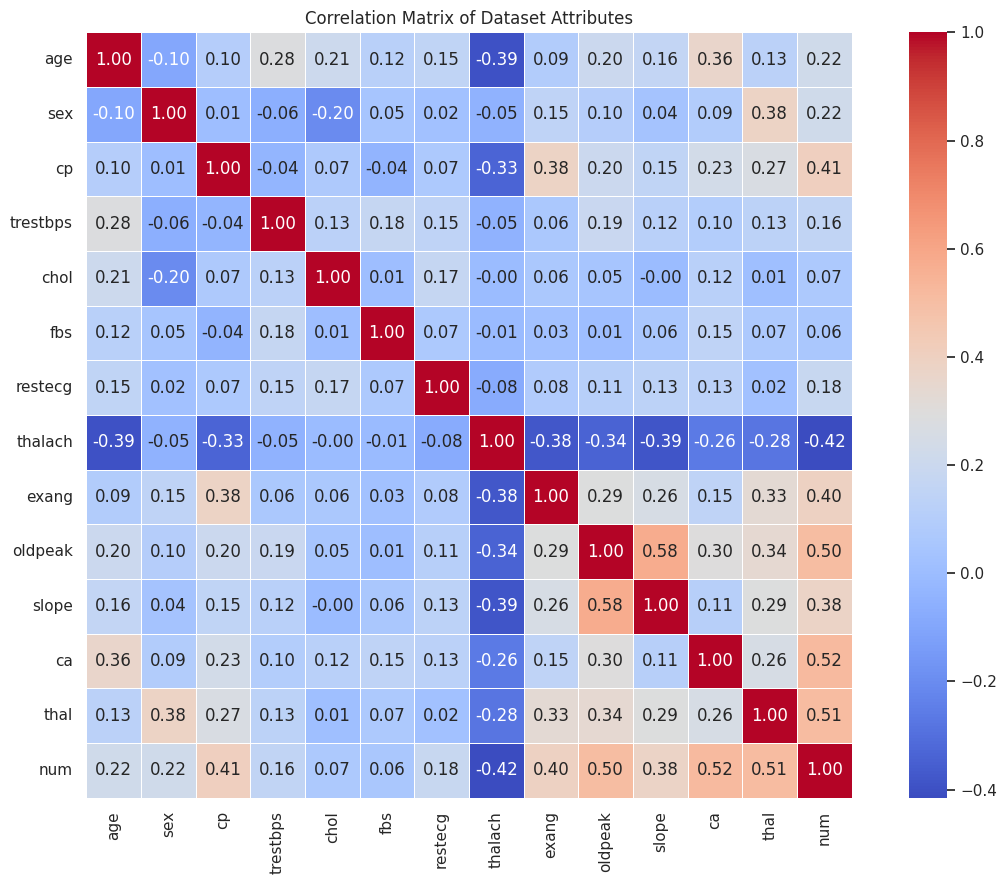


10. FINAL DATA EXPLORATION SUMMARY
Total records: 303
Total attributes: 14
Predictor attributes: 13
Missing cells: 6
Duplicate records: 0

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Continuous features: 5
Categorical features: 8

STEP 2: DATA EXPLORATION COMPLETED SUCCESSFULLY


In [15]:

# ================================================================
# STEP 2: DATA EXPLORATION AND STATISTICAL ANALYSIS
# Research: Heart Disease Prediction Using Machine Learning
# Dataset: UCI Cleveland Heart Disease Dataset
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

# ------------------------------------------------
# 1. DATASET DIMENSIONS
# ------------------------------------------------

print("\n" + "=" * 70)
print("1. DATASET DIMENSIONS")
print("=" * 70)

print("Total observations:", df.shape[0])
print("Total attributes:", df.shape[1])
print("Dataset shape:", df.shape)


# ------------------------------------------------
# 2. DATASET STRUCTURE
# ------------------------------------------------

print("\n" + "=" * 70)
print("2. DATASET STRUCTURE")
print("=" * 70)

print("\nDataset information:")
df.info()

print("\nFirst five records:")
print(df.head())

print("\nLast five records:")
print(df.tail())


# ------------------------------------------------
# 3. DESCRIPTIVE STATISTICAL ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("3. DESCRIPTIVE STATISTICAL ANALYSIS")
print("=" * 70)

descriptive_stats = df.describe().T

descriptive_stats = descriptive_stats.round(2)

print(descriptive_stats)


# ------------------------------------------------
# 4. DATA TYPE AND FEATURE CLASSIFICATION
# ------------------------------------------------

print("\n" + "=" * 70)
print("4. DATA TYPE AND FEATURE CLASSIFICATION")
print("=" * 70)

print("\nData types:")
print(df.dtypes)

continuous_features = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

feature_classification = pd.DataFrame({
    'Feature': continuous_features + categorical_features,
    'Feature Type': (
        ['Continuous'] * len(continuous_features) +
        ['Categorical'] * len(categorical_features)
    )
})

print("\nFeature classification:")
print(feature_classification.to_string(index=False))


# ------------------------------------------------
# 5. MISSING VALUE ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("5. MISSING VALUE ANALYSIS")
print("=" * 70)

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    )
})

print("\nMissing value summary:")
print(missing_summary.round(2))

print("\nTotal missing cells:",
      df.isnull().sum().sum())

print("Rows containing missing values:",
      df.isnull().any(axis=1).sum())

print("\nRecords containing missing values:")
print(df[df.isnull().any(axis=1)])


# ------------------------------------------------
# 6. DUPLICATE RECORD ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("6. DUPLICATE RECORD ANALYSIS")
print("=" * 70)

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)


# ------------------------------------------------
# 7. ORIGINAL TARGET VARIABLE DISTRIBUTION
# ------------------------------------------------

print("\n" + "=" * 70)
print("7. ORIGINAL TARGET VARIABLE DISTRIBUTION")
print("=" * 70)

target_counts = df['num'].value_counts().sort_index()

target_summary = pd.DataFrame({
    'Target Category': target_counts.index,
    'Number of Records': target_counts.values,
    'Percentage': (
        target_counts.values / len(df) * 100
    ).round(2)
})

print(target_summary.to_string(index=False))

print("\nTotal observations:", target_counts.sum())


# ------------------------------------------------
# 8. UNIQUE VALUE ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("8. UNIQUE VALUE ANALYSIS")
print("=" * 70)

unique_summary = pd.DataFrame({
    'Attribute': df.columns,
    'Unique Values': [
        df[column].nunique() for column in df.columns
    ]
})

print(unique_summary.to_string(index=False))

print("\nDistinct values in each attribute:")

for column in df.columns:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().unique()))


# ================================================================
# 9. DATASET VISUALIZATIONS
# ================================================================

# ------------------------------------------------
# FIGURE 1: ORIGINAL TARGET DISTRIBUTION
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='num',
    hue='num',
    palette='viridis',
    legend=False
)

plt.title(
    'Distribution of Original Heart Disease Target',
    fontsize=13
)

plt.xlabel('Target Category (num)')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.savefig('step2_figure1_target_distribution.png', dpi=300)
plt.show()


# ------------------------------------------------
# FIGURE 2: MISSING VALUE DISTRIBUTION
# ------------------------------------------------

missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(7, 5))

if len(missing_values) > 0:

    sns.barplot(
        x=missing_values.index,
        y=missing_values.values,
        hue=missing_values.index,
        palette='magma',
        legend=False
    )

    plt.title('Missing Values Across Dataset Attributes')
    plt.xlabel('Attributes')
    plt.ylabel('Number of Missing Values')

else:
    plt.text(
        0.5, 0.5,
        'No missing values found',
        ha='center',
        va='center'
    )
    plt.axis('off')

plt.tight_layout()
plt.savefig('step2_figure2_missing_values.png', dpi=300)
plt.show()


# ------------------------------------------------
# FIGURE 3: DISTRIBUTION OF CONTINUOUS FEATURES
# ------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), continuous_features):

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')

# Hide the unused sixth subplot
axes.flatten()[-1].set_visible(False)

plt.suptitle(
    'Distribution of Continuous Attributes',
    fontsize=15
)

plt.tight_layout()
plt.savefig('step2_figure3_continuous_features.png', dpi=300)
plt.show()


# ------------------------------------------------
# FIGURE 4: CORRELATION MATRIX
# ------------------------------------------------

plt.figure(figsize=(12, 9))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Matrix of Dataset Attributes')

plt.tight_layout()
plt.savefig('step2_figure4_correlation_matrix.png', dpi=300)
plt.show()


# ================================================================
# 10. FINAL DATA EXPLORATION SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("10. FINAL DATA EXPLORATION SUMMARY")
print("=" * 70)

print("Total records:", len(df))
print("Total attributes:", len(df.columns))
print("Predictor attributes:", len(df.columns) - 1)
print("Missing cells:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nOriginal target distribution:")
print(target_counts)

print("\nContinuous features:", len(continuous_features))
print("Categorical features:", len(categorical_features))

print("\nSTEP 2: DATA EXPLORATION COMPLETED SUCCESSFULLY")

# ================================================================
# END OF STEP 2
# ================================================================


**STEP 3: DATA PREPROCESSING**

In [16]:

# ================================================================
# STEP 3: DATA PREPROCESSING
# Research: Heart Disease Prediction Using Machine Learning
# ================================================================

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ------------------------------------------------
# 1. SEPARATE PREDICTORS AND ORIGINAL TARGET
# ------------------------------------------------

print("=" * 70)
print("1. SEPARATING FEATURES AND TARGET")
print("=" * 70)

# Keep the original target unchanged for now
X = df.drop(columns=['num']).copy()
y_original = df['num'].copy()

print("Feature matrix shape:", X.shape)
print("Original target shape:", y_original.shape)


# ------------------------------------------------
# 2. FEATURE CLASSIFICATION
# ------------------------------------------------

print("\n" + "=" * 70)
print("2. FEATURE CLASSIFICATION")
print("=" * 70)

continuous_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

print("Continuous features:", continuous_features)
print("Categorical features:", categorical_features)

print("\nTotal continuous features:", len(continuous_features))
print("Total categorical features:", len(categorical_features))


# ------------------------------------------------
# 3. DEFINE CONTINUOUS FEATURE PREPROCESSING
# ------------------------------------------------

print("\n" + "=" * 70)
print("3. CONTINUOUS FEATURE PREPROCESSING")
print("=" * 70)

continuous_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# ------------------------------------------------
# 4. DEFINE CATEGORICAL FEATURE PREPROCESSING
# ------------------------------------------------

print("\n" + "=" * 70)
print("4. CATEGORICAL FEATURE PREPROCESSING")
print("=" * 70)

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])


# ------------------------------------------------
# 5. COMBINE PREPROCESSING PIPELINES
# ------------------------------------------------

print("\n" + "=" * 70)
print("5. COMBINING PREPROCESSING PIPELINES")
print("=" * 70)

preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', continuous_pipeline, continuous_features),
        ('categorical', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)

print("Preprocessing pipeline created successfully.")
print("\nPipeline configuration:")
print(preprocessor)


# ------------------------------------------------
# 6. PREPROCESSING CONFIGURATION SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("6. PREPROCESSING CONFIGURATION SUMMARY")
print("=" * 70)

preprocessing_summary = pd.DataFrame({
    'Feature Group': [
        'Continuous',
        'Categorical'
    ],
    'Number of Features': [
        len(continuous_features),
        len(categorical_features)
    ],
    'Missing Value Treatment': [
        'Median Imputation',
        'Most Frequent Imputation'
    ],
    'Transformation': [
        'Standard Scaling',
        'One-Hot Encoding'
    ]
})

print(preprocessing_summary.to_string(index=False))


# ------------------------------------------------
# 7. CHECK MISSING VALUES IN ORIGINAL FEATURES
# ------------------------------------------------

print("\n" + "=" * 70)
print("7. ORIGINAL MISSING VALUE VERIFICATION")
print("=" * 70)

print("Missing values before preprocessing:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nTotal missing cells:", X.isnull().sum().sum())


# ------------------------------------------------
# 8. VERIFY PREPROCESSING ON A SMALL DEMONSTRATION
# ------------------------------------------------

print("\n" + "=" * 70)
print("8. PREPROCESSING PIPELINE VERIFICATION")
print("=" * 70)

# This demonstration only checks that the pipeline works.
# It does not replace the later train/test and CV workflow.

demo_preprocessor = preprocessor

demo_transformed = demo_preprocessor.fit_transform(X)

print("Original feature shape:", X.shape)
print("Transformed feature shape:", demo_transformed.shape)

print("\nMissing values after demonstration transformation:",
      np.isnan(demo_transformed).sum())

print("\nFirst five transformed records:")
print(pd.DataFrame(demo_transformed).head())


# ------------------------------------------------
# 9. FINAL PREPROCESSING SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("9. FINAL PREPROCESSING SUMMARY")
print("=" * 70)

print("Original records:", len(X))
print("Original predictor features:", X.shape[1])
print("Continuous features:", len(continuous_features))
print("Categorical features:", len(categorical_features))
print("Transformed features:", demo_transformed.shape[1])

print("\nMissing-value strategy:")
print("Continuous features: Median imputation")
print("Categorical features: Most-frequent imputation")

print("\nScaling: StandardScaler")
print("Categorical encoding: OneHotEncoder")

print("\nSTEP 3: DATA PREPROCESSING COMPLETED SUCCESSFULLY")

# ================================================================
# END OF STEP 3
# ================================================================


1. SEPARATING FEATURES AND TARGET
Feature matrix shape: (303, 13)
Original target shape: (303,)

2. FEATURE CLASSIFICATION
Continuous features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Total continuous features: 5
Total categorical features: 8

3. CONTINUOUS FEATURE PREPROCESSING

4. CATEGORICAL FEATURE PREPROCESSING

5. COMBINING PREPROCESSING PIPELINES
Preprocessing pipeline created successfully.

Pipeline configuration:
ColumnTransformer(transformers=[('continuous',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('categorical',
                                 Pip

**STEP 4: TARGET PREPARATION AND BINARY CLASSIFICATION**

1. ORIGINAL TARGET VARIABLE
Original target categories:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

2. BINARY TARGET CONVERSION
Binary target created successfully.

Target mapping:
Original value 0     -> Binary class 0
Original values 1-4  -> Binary class 1

3. BINARY TARGET VERIFICATION
Unique binary classes: [np.int64(0), np.int64(1)]
Target data type: int64
Total observations: 303

Binary target verification successful.

4. BINARY CLASS DISTRIBUTION
 Class         Class Description  Number of Records  Percentage
     0  Absence of Heart Disease                164       54.13
     1 Presence of Heart Disease                139       45.87

5. CLASS BALANCE ANALYSIS
Class 0 percentage: 54.13%
Class 1 percentage: 45.87%
Majority-to-minority class ratio: 1.18:1
Observation: The classes are relatively balanced.


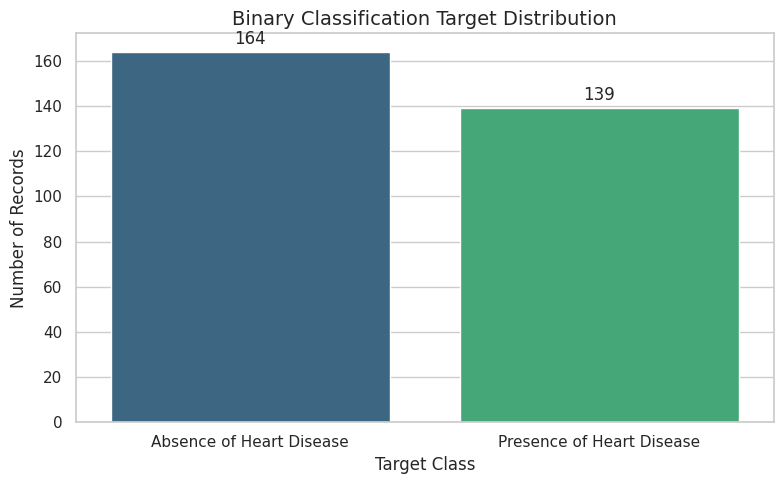


7. FINAL FEATURE AND TARGET VERIFICATION
Feature matrix shape: (303, 13)
Binary target shape: (303,)
Original target retained separately: (303,)

Feature-target separation verified.

8. FINAL TARGET PREPARATION SUMMARY
Total records: 303
Number of binary classes: 2

Class 0 - Absence of Heart Disease: 164
Class 1 - Presence of Heart Disease: 139

Final feature matrix: (303, 13)
Final target vector: (303,)

STEP 4: TARGET PREPARATION COMPLETED SUCCESSFULLY


In [17]:

# ================================================================
# STEP 4: TARGET PREPARATION AND BINARY CLASSIFICATION
# Research: Heart Disease Prediction Using Machine Learning
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ------------------------------------------------
# 1. RETAIN ORIGINAL TARGET VARIABLE
# ------------------------------------------------

print("=" * 70)
print("1. ORIGINAL TARGET VARIABLE")
print("=" * 70)

y_original = df['num'].copy()

print("Original target categories:")
print(sorted(y_original.unique()))

print("\nOriginal target distribution:")
print(y_original.value_counts().sort_index())


# ------------------------------------------------
# 2. CONVERT ORIGINAL TARGET INTO BINARY CLASSES
# ------------------------------------------------

print("\n" + "=" * 70)
print("2. BINARY TARGET CONVERSION")
print("=" * 70)

# 0 = Absence of heart disease
# 1, 2, 3, 4 = Presence of heart disease

y = (y_original > 0).astype(int)

print("Binary target created successfully.")

print("\nTarget mapping:")
print("Original value 0     -> Binary class 0")
print("Original values 1-4  -> Binary class 1")


# ------------------------------------------------
# 3. VERIFY BINARY TARGET VALUES
# ------------------------------------------------

print("\n" + "=" * 70)
print("3. BINARY TARGET VERIFICATION")
print("=" * 70)

print("Unique binary classes:", sorted(y.unique()))
print("Target data type:", y.dtype)
print("Total observations:", len(y))

assert set(y.unique()) == {0, 1}, \
    "Target conversion error: expected classes 0 and 1."

assert len(y) == len(df), \
    "Target length does not match dataset length."

print("\nBinary target verification successful.")


# ------------------------------------------------
# 4. CALCULATE CLASS DISTRIBUTION
# ------------------------------------------------

print("\n" + "=" * 70)
print("4. BINARY CLASS DISTRIBUTION")
print("=" * 70)

class_counts = y.value_counts().sort_index()

class_summary = pd.DataFrame({
    'Class': class_counts.index,
    'Class Description': [
        'Absence of Heart Disease',
        'Presence of Heart Disease'
    ],
    'Number of Records': class_counts.values,
    'Percentage': (
        class_counts.values / len(y) * 100
    ).round(2)
})

print(class_summary.to_string(index=False))


# ------------------------------------------------
# 5. CLASS BALANCE ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 70)
print("5. CLASS BALANCE ANALYSIS")
print("=" * 70)

class_0_percentage = (y == 0).mean() * 100
class_1_percentage = (y == 1).mean() * 100

print(f"Class 0 percentage: {class_0_percentage:.2f}%")
print(f"Class 1 percentage: {class_1_percentage:.2f}%")

class_ratio = class_counts.max() / class_counts.min()

print(f"Majority-to-minority class ratio: {class_ratio:.2f}:1")

if class_ratio < 1.5:
    print("Observation: The classes are relatively balanced.")
else:
    print("Observation: The dataset shows class imbalance.")


# ------------------------------------------------
# 6. VISUALIZE BINARY TARGET DISTRIBUTION
# ------------------------------------------------

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=y,
    hue=y,
    palette='viridis',
    legend=False
)

plt.title(
    'Binary Classification Target Distribution',
    fontsize=14
)

plt.xlabel('Target Class')
plt.ylabel('Number of Records')

plt.xticks(
    ticks=[0, 1],
    labels=[
        'Absence of Heart Disease',
        'Presence of Heart Disease'
    ]
)

# Add record counts above bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()

plt.savefig(
    'step4_binary_target_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------
# 7. CREATE FINAL FEATURE AND TARGET VARIABLES
# ------------------------------------------------

print("\n" + "=" * 70)
print("7. FINAL FEATURE AND TARGET VERIFICATION")
print("=" * 70)

# Predictor matrix remains unchanged
X = df.drop(columns=['num']).copy()

# Binary target
y = y.copy()

print("Feature matrix shape:", X.shape)
print("Binary target shape:", y.shape)

print("Original target retained separately:",
      y_original.shape)

assert 'num' not in X.columns
assert len(X) == len(y)

print("\nFeature-target separation verified.")


# ------------------------------------------------
# 8. FINAL TARGET PREPARATION SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("8. FINAL TARGET PREPARATION SUMMARY")
print("=" * 70)

print("Total records:", len(df))
print("Number of binary classes:", y.nunique())

print("\nClass 0 - Absence of Heart Disease:",
      (y == 0).sum())

print("Class 1 - Presence of Heart Disease:",
      (y == 1).sum())

print("\nFinal feature matrix:", X.shape)
print("Final target vector:", y.shape)

print("\nSTEP 4: TARGET PREPARATION COMPLETED SUCCESSFULLY")

# ================================================================
# END OF STEP 4
# ================================================================


**STEP 5: EXPLORATORY DATA ANALYSIS (EDA)**

1. PREPARING DATA FOR EXPLORATORY ANALYSIS
EDA dataset shape: (303, 14)
Total observations: 303

Target class distribution:
HeartDisease
0    164
1    139
Name: count, dtype: int64

2. CONTINUOUS FEATURE ANALYSIS

Continuous feature statistics grouped by target:
                age                          trestbps                                chol                             thalach                            oldpeak                       
               mean median   std   min   max     mean median    std    min    max    mean median    std    min    max    mean median    std   min    max    mean median   std  min  max
HeartDisease                                                                                                                                                                           
0             52.59   52.0  9.51  29.0  76.0   129.25  130.0  16.20   94.0  180.0  242.64  234.5  53.46  126.0  564.0  158.38  161.0  19.20  96.0  202.0    0.59    0.2  0.78  0.0  4.2
1

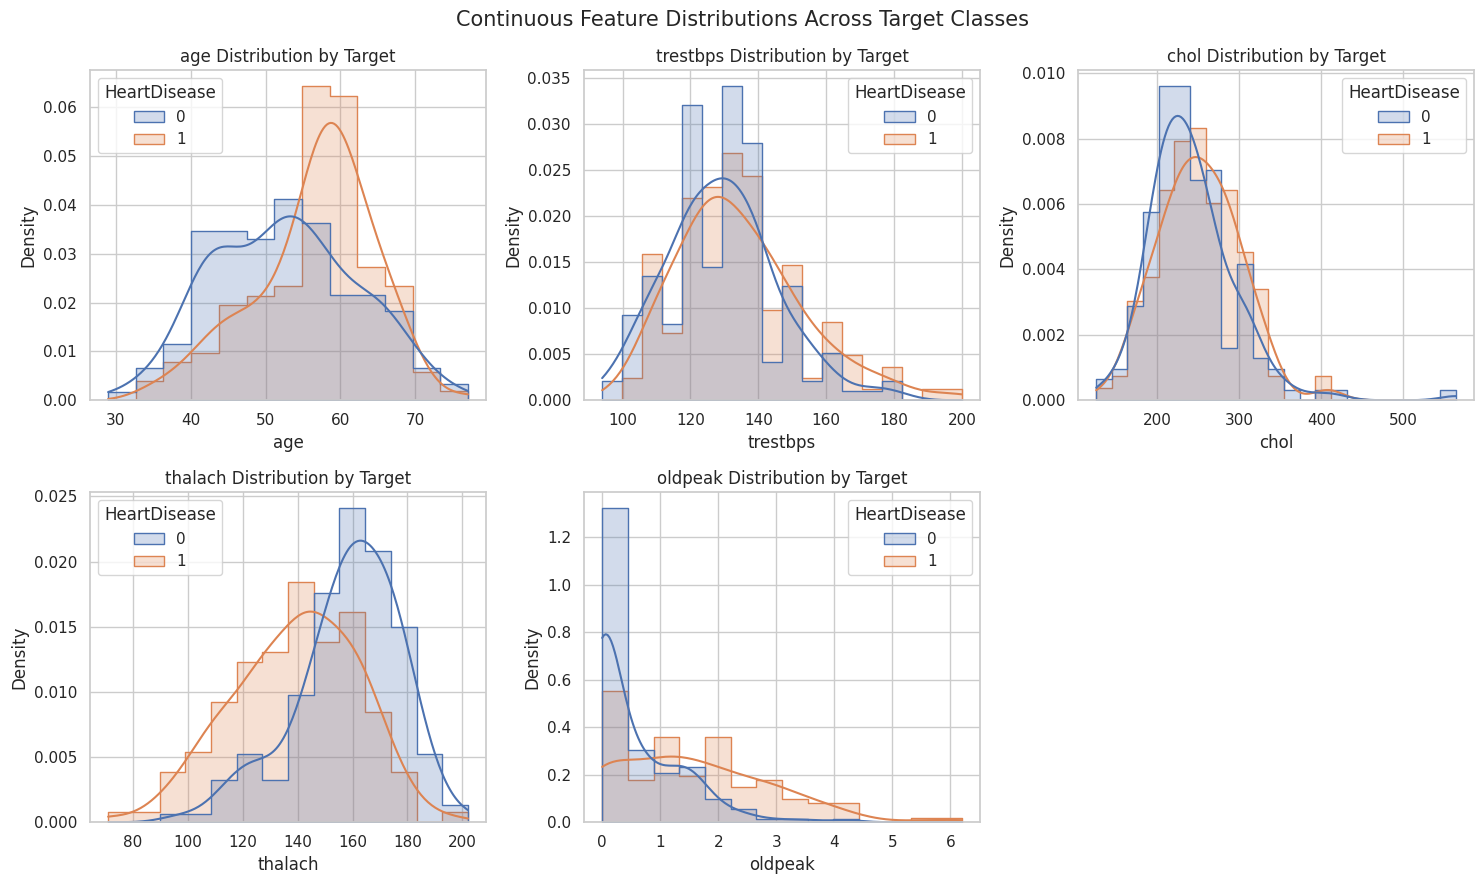


5. BOXPLOT ANALYSIS


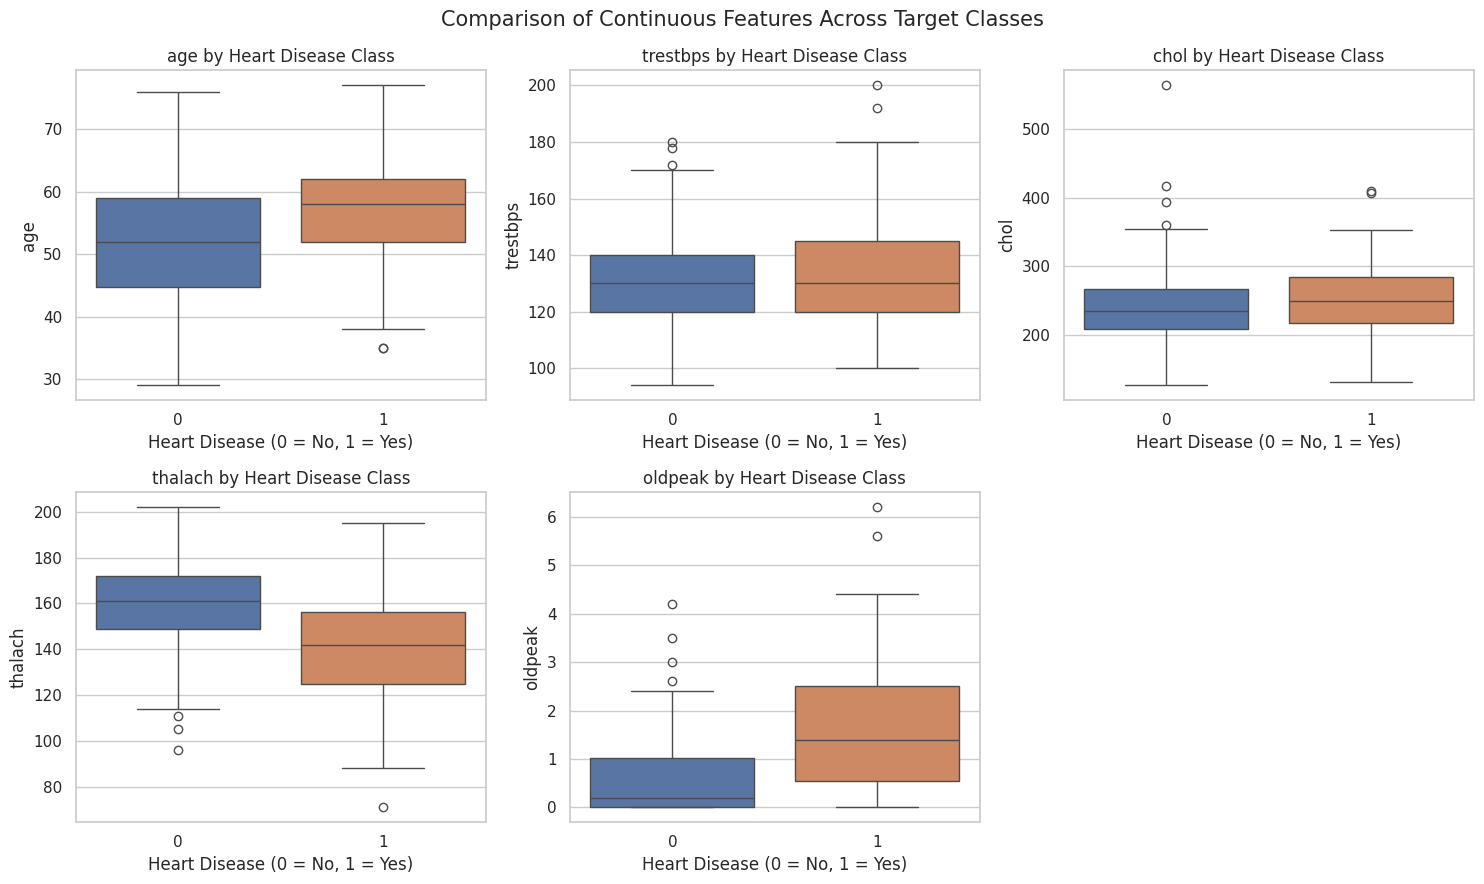


6. CATEGORICAL FEATURE DISTRIBUTIONS


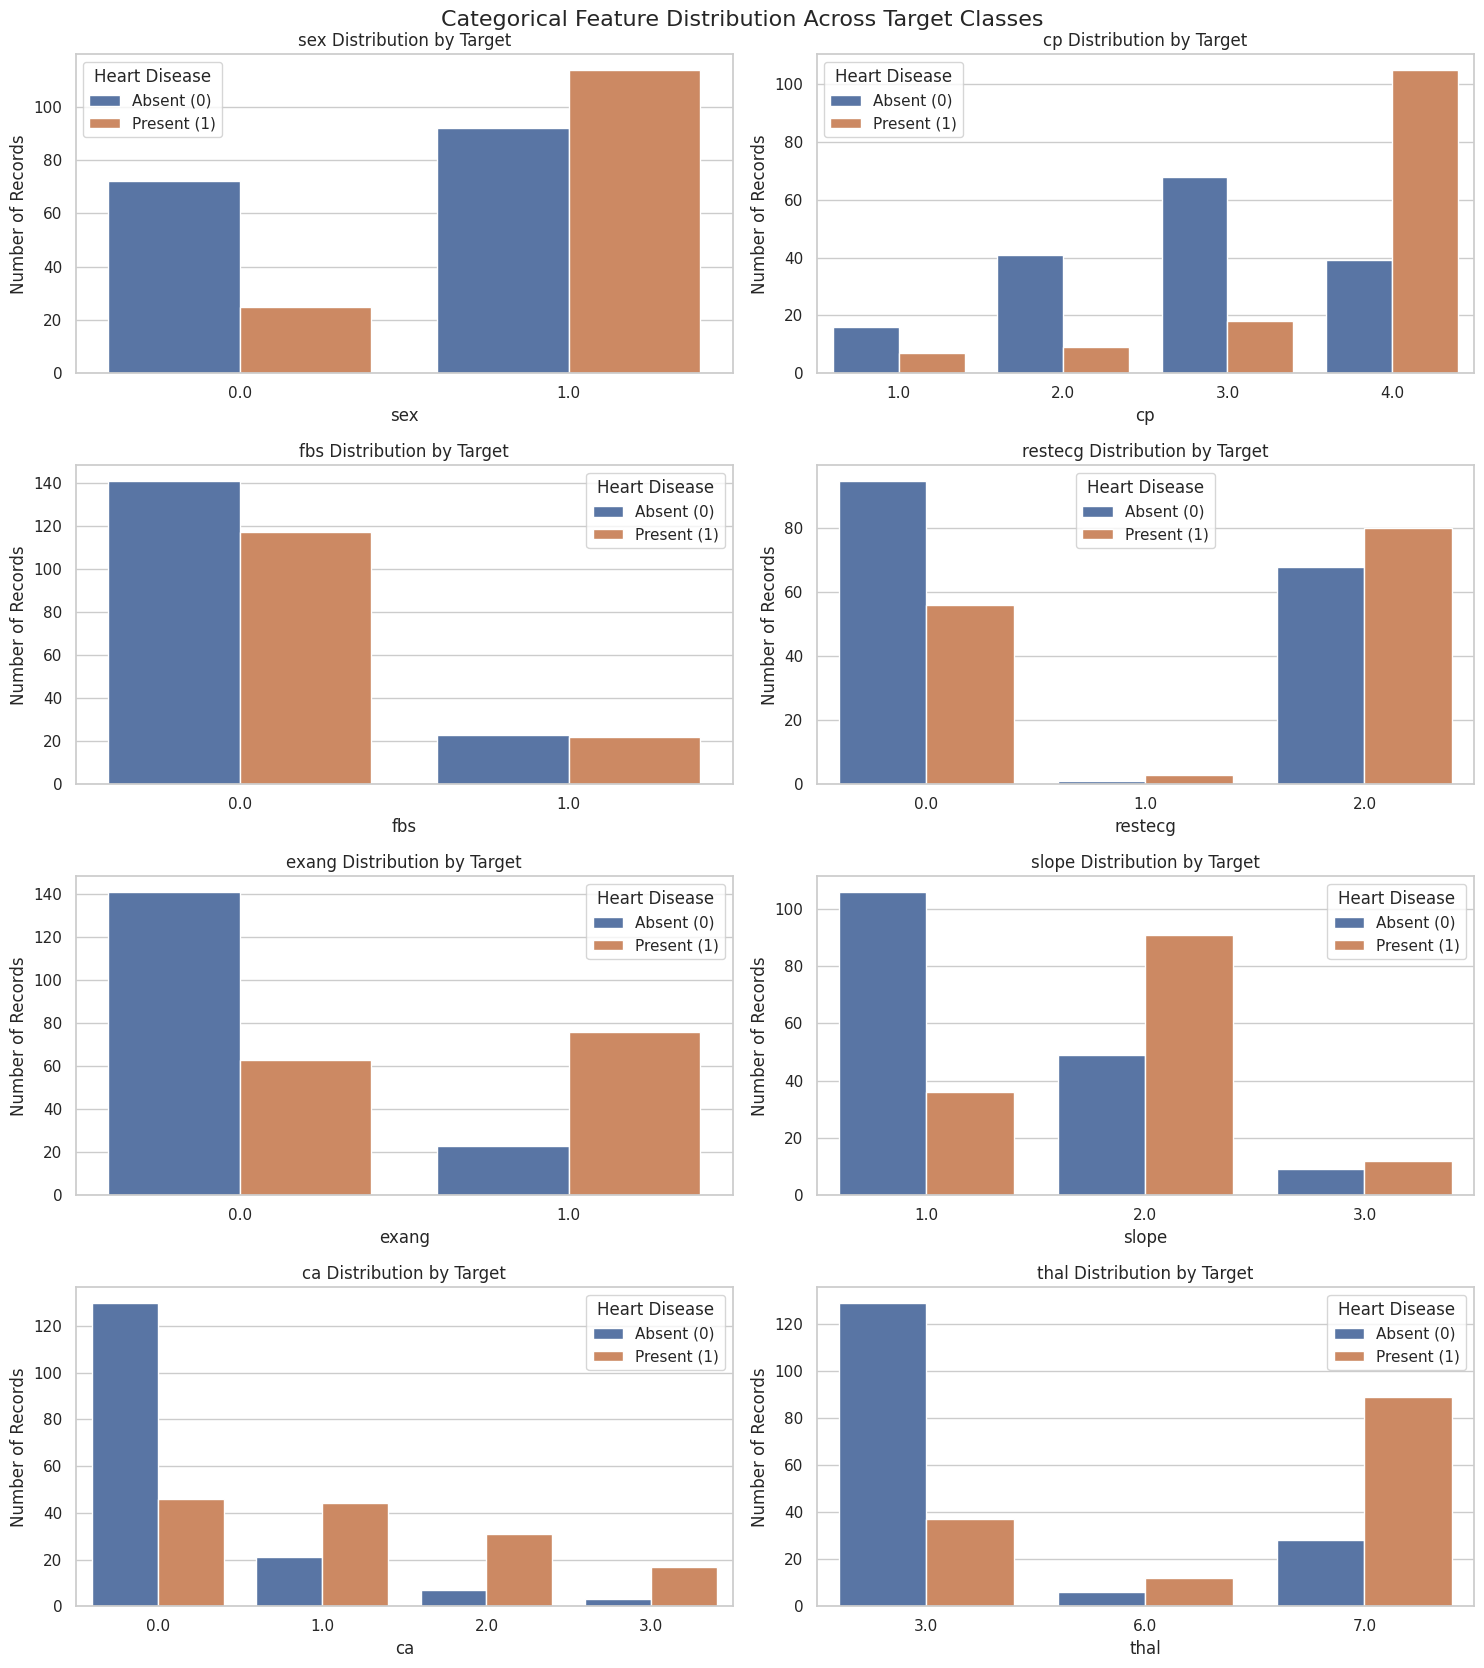


7. CATEGORICAL CLASS PROPORTION ANALYSIS

Class-wise percentage distribution for sex:
HeartDisease     0      1
sex                      
0.0           43.9  17.99
1.0           56.1  82.01

Class-wise percentage distribution for cp:
HeartDisease      0      1
cp                        
1.0            9.76   5.04
2.0           25.00   6.47
3.0           41.46  12.95
4.0           23.78  75.54

Class-wise percentage distribution for fbs:
HeartDisease      0      1
fbs                       
0.0           85.98  84.17
1.0           14.02  15.83

Class-wise percentage distribution for restecg:
HeartDisease      0      1
restecg                   
0.0           57.93  40.29
1.0            0.61   2.16
2.0           41.46  57.55

Class-wise percentage distribution for exang:
HeartDisease      0      1
exang                     
0.0           85.98  45.32
1.0           14.02  54.68

Class-wise percentage distribution for slope:
HeartDisease      0      1
slope                     
1.0       

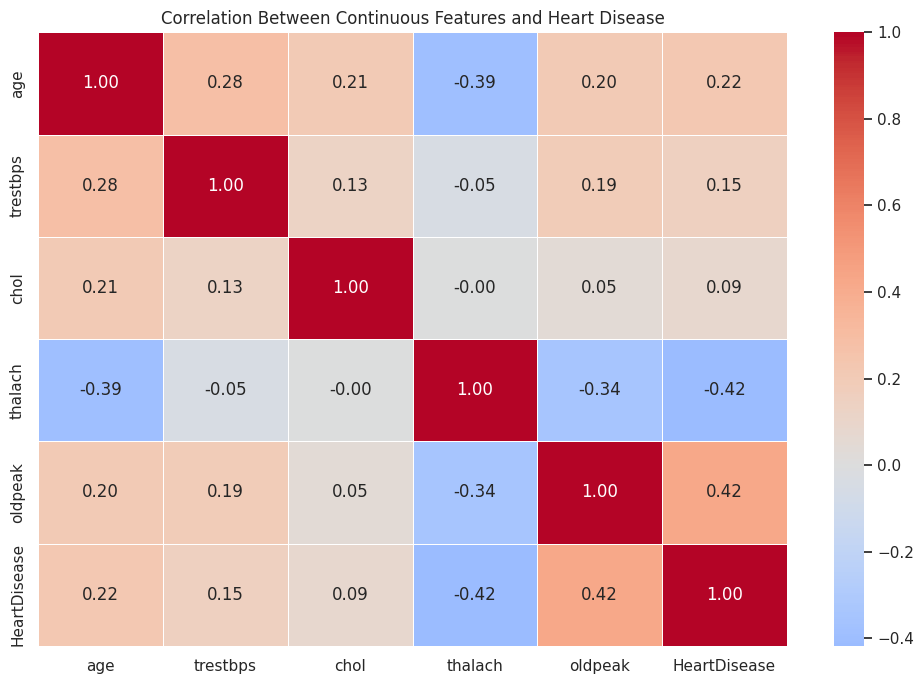


10. MISSING VALUE REVIEW DURING EDA
ca      4
thal    2
dtype: int64

Note: Missing values are retained in this analysis.
They will be handled through the preprocessing pipeline.

11. FINAL EDA SUMMARY
Total observations: 303
Continuous features analysed: 5
Categorical features analysed: 8

Target distribution:
HeartDisease
0    164
1    139
Name: count, dtype: int64

Continuous features analysed:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features analysed:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

STEP 5: EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY


In [18]:

# ================================================================
# STEP 5: EXPLORATORY DATA ANALYSIS (EDA)
# Research: Heart Disease Prediction Using Machine Learning
# Dataset: UCI Cleveland Heart Disease Dataset
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ------------------------------------------------
# 1. PREPARE DATA FOR EXPLORATORY ANALYSIS
# ------------------------------------------------

print("=" * 75)
print("1. PREPARING DATA FOR EXPLORATORY ANALYSIS")
print("=" * 75)

# Combine predictors and binary target for analysis only
eda_df = X.copy()
eda_df['HeartDisease'] = y.values

print("EDA dataset shape:", eda_df.shape)
print("Total observations:", len(eda_df))

print("\nTarget class distribution:")
print(eda_df['HeartDisease'].value_counts().sort_index())


# ------------------------------------------------
# 2. CONTINUOUS FEATURE ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 75)
print("2. CONTINUOUS FEATURE ANALYSIS")
print("=" * 75)

continuous_features = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

continuous_summary = (
    eda_df.groupby('HeartDisease')[continuous_features]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

print("\nContinuous feature statistics grouped by target:")
print(continuous_summary.to_string())


# ------------------------------------------------
# 3. CATEGORICAL FEATURE ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 75)
print("3. CATEGORICAL FEATURE ANALYSIS")
print("=" * 75)

categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

for feature in categorical_features:

    print(f"\nDistribution of {feature} by target:")

    category_table = pd.crosstab(
        eda_df[feature],
        eda_df['HeartDisease'],
        margins=True
    )

    print(category_table)


# ------------------------------------------------
# 4. CLASS-WISE DISTRIBUTION OF CONTINUOUS FEATURES
# ------------------------------------------------

print("\n" + "=" * 75)
print("4. CLASS-WISE CONTINUOUS FEATURE DISTRIBUTION")
print("=" * 75)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), continuous_features):

    sns.histplot(
        data=eda_df,
        x=feature,
        hue='HeartDisease',
        kde=True,
        element='step',
        stat='density',
        common_norm=False,
        ax=ax
    )

    ax.set_title(f'{feature} Distribution by Target')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')

axes.flatten()[-1].set_visible(False)

plt.suptitle(
    'Continuous Feature Distributions Across Target Classes',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    'step5_figure1_continuous_distributions.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------
# 5. BOXPLOT ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 75)
print("5. BOXPLOT ANALYSIS")
print("=" * 75)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), continuous_features):

    sns.boxplot(
        data=eda_df,
        x='HeartDisease',
        y=feature,
        hue='HeartDisease',
        legend=False,
        ax=ax
    )

    ax.set_title(f'{feature} by Heart Disease Class')
    ax.set_xlabel('Heart Disease (0 = No, 1 = Yes)')
    ax.set_ylabel(feature)

axes.flatten()[-1].set_visible(False)

plt.suptitle(
    'Comparison of Continuous Features Across Target Classes',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    'step5_figure2_boxplots.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------
# 6. CATEGORICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------

print("\n" + "=" * 75)
print("6. CATEGORICAL FEATURE DISTRIBUTIONS")
print("=" * 75)

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for ax, feature in zip(axes.flatten(), categorical_features):

    sns.countplot(
        data=eda_df,
        x=feature,
        hue='HeartDisease',
        ax=ax
    )

    ax.set_title(f'{feature} Distribution by Target')
    ax.set_xlabel(feature)
    ax.set_ylabel('Number of Records')
    ax.legend(
        title='Heart Disease',
        labels=['Absent (0)', 'Present (1)']
    )

plt.suptitle(
    'Categorical Feature Distribution Across Target Classes',
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    'step5_figure3_categorical_distributions.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------
# 7. CATEGORICAL CLASS PROPORTION ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 75)
print("7. CATEGORICAL CLASS PROPORTION ANALYSIS")
print("=" * 75)

for feature in categorical_features:

    print(f"\nClass-wise percentage distribution for {feature}:")

    proportion_table = pd.crosstab(
        eda_df[feature],
        eda_df['HeartDisease'],
        normalize='columns'
    ) * 100

    print(proportion_table.round(2))


# ------------------------------------------------
# 8. CORRELATION ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 75)
print("8. CONTINUOUS FEATURE CORRELATION ANALYSIS")
print("=" * 75)

correlation_features = continuous_features + ['HeartDisease']

correlation_matrix = eda_df[
    correlation_features
].corr()

print("\nCorrelation matrix:")
print(correlation_matrix.round(3))


# ------------------------------------------------
# 9. CORRELATION HEATMAP
# ------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title(
    'Correlation Between Continuous Features and Heart Disease'
)

plt.tight_layout()

plt.savefig(
    'step5_figure4_correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------
# 10. FEATURE-WISE MISSING VALUE REVIEW
# ------------------------------------------------

print("\n" + "=" * 75)
print("10. MISSING VALUE REVIEW DURING EDA")
print("=" * 75)

eda_missing = eda_df.isnull().sum()

print(eda_missing[eda_missing > 0])

print("\nNote: Missing values are retained in this analysis.")
print("They will be handled through the preprocessing pipeline.")


# ------------------------------------------------
# 11. FINAL EDA SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("11. FINAL EDA SUMMARY")
print("=" * 75)

print("Total observations:", len(eda_df))
print("Continuous features analysed:", len(continuous_features))
print("Categorical features analysed:", len(categorical_features))

print("\nTarget distribution:")
print(eda_df['HeartDisease'].value_counts().sort_index())

print("\nContinuous features analysed:")
print(continuous_features)

print("\nCategorical features analysed:")
print(categorical_features)

print("\nSTEP 5: EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY")

# ================================================================
# END OF STEP 5
# ================================================================


**STEP 6: DATA SPLITTING**

In [19]:
# ============================================================
# STEP 6: DATA SPLITTING
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 70)
print("STEP 6: DATA SPLITTING")
print("=" * 70)

# 1. Verify the input dataset
print("\n1. ORIGINAL DATASET INFORMATION")
print("-" * 70)

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)
print("Total observations:", len(X))

# 2. Split the dataset into training and testing sets
# 80% training data and 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Display the dimensions of the resulting datasets
print("\n2. TRAIN-TEST SPLIT DIMENSIONS")
print("-" * 70)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# 4. Calculate class distributions
print("\n3. TRAINING SET CLASS DISTRIBUTION")
print("-" * 70)

train_distribution = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percentage": (
        y_train.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

train_distribution.index.name = "HeartDisease"
print(train_distribution)

print("\n4. TESTING SET CLASS DISTRIBUTION")
print("-" * 70)

test_distribution = pd.DataFrame({
    "Count": y_test.value_counts().sort_index(),
    "Percentage": (
        y_test.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

test_distribution.index.name = "HeartDisease"
print(test_distribution)

# 5. Compare the original, training and testing distributions
print("\n5. CLASS DISTRIBUTION COMPARISON")
print("-" * 70)

comparison = pd.DataFrame({
    "Original Dataset": y.value_counts().sort_index(),
    "Training Set": y_train.value_counts().sort_index(),
    "Testing Set": y_test.value_counts().sort_index()
})

comparison.index.name = "HeartDisease"
print(comparison)

# 6. Verify the split
print("\n6. SPLIT VERIFICATION")
print("-" * 70)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total observations after splitting:",
      len(X_train) + len(X_test))

print("Training data contains missing values:", X_train.isnull().sum().sum() > 0)
print("Testing data contains missing values:", X_test.isnull().sum().sum() > 0)

print("\nNote:")
print("Missing values are intentionally retained at this stage.")
print("They will be handled by the preprocessing pipeline during model training.")

print("\nSTEP 6: DATA SPLITTING COMPLETED SUCCESSFULLY")

STEP 6: DATA SPLITTING

1. ORIGINAL DATASET INFORMATION
----------------------------------------------------------------------
Input features shape: (303, 13)
Target variable shape: (303,)
Total observations: 303

2. TRAIN-TEST SPLIT DIMENSIONS
----------------------------------------------------------------------
X_train shape: (242, 13)
X_test shape: (61, 13)
y_train shape: (242,)
y_test shape: (61,)

3. TRAINING SET CLASS DISTRIBUTION
----------------------------------------------------------------------
              Count  Percentage
HeartDisease                   
0               131       54.13
1               111       45.87

4. TESTING SET CLASS DISTRIBUTION
----------------------------------------------------------------------
              Count  Percentage
HeartDisease                   
0                33        54.1
1                28        45.9

5. CLASS DISTRIBUTION COMPARISON
----------------------------------------------------------------------
              Origin

**STEP 7: MODEL DEVELOPMENT**

In [20]:
# ============================================================
# STEP 7: MODEL DEVELOPMENT
# ============================================================

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("STEP 7: MODEL DEVELOPMENT")
print("=" * 70)

# 1. Define the selected machine-learning algorithms

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    )
}

# 2. Create a separate preprocessing and classification pipeline
# for each machine-learning algorithm.

model_pipelines = {}

for model_name, classifier in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    model_pipelines[model_name] = model_pipeline


# 3. Display the developed models

print("\n1. DEVELOPED MACHINE-LEARNING MODELS")
print("-" * 70)

for model_name, pipeline in model_pipelines.items():

    print("\nModel:", model_name)
    print("Pipeline steps:", list(pipeline.named_steps.keys()))
    print("Classifier:", pipeline.named_steps["classifier"])


# 4. Display the model configuration summary

model_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Algorithm Type": [
        "Linear Classification",
        "Tree-Based Classification",
        "Ensemble Classification"
    ],

    "Configuration": [
        "Maximum iterations = 2000",
        "Random state = 42",
        "300 decision trees, random state = 42"
    ]
})

print("\n2. MODEL CONFIGURATION SUMMARY")
print("-" * 70)
print(model_summary.to_string(index=False))


# 5. Verify that all models are ready for training

print("\n3. MODEL PIPELINE VERIFICATION")
print("-" * 70)

for model_name, pipeline in model_pipelines.items():

    print(model_name, ":", "Successfully created")


print("\nNumber of models developed:", len(model_pipelines))

print("\nTraining observations available:", len(X_train))
print("Testing observations reserved:", len(X_test))

print("\nIMPORTANT:")
print("The models have been defined but have not been fitted yet.")
print("Training and validation will be performed in the next stages.")

print("\nSTEP 7: MODEL DEVELOPMENT COMPLETED SUCCESSFULLY")

STEP 7: MODEL DEVELOPMENT

1. DEVELOPED MACHINE-LEARNING MODELS
----------------------------------------------------------------------

Model: Logistic Regression
Pipeline steps: ['preprocessing', 'classifier']
Classifier: LogisticRegression(max_iter=2000, random_state=42)

Model: Decision Tree
Pipeline steps: ['preprocessing', 'classifier']
Classifier: DecisionTreeClassifier(random_state=42)

Model: Random Forest
Pipeline steps: ['preprocessing', 'classifier']
Classifier: RandomForestClassifier(n_estimators=300, random_state=42)

2. MODEL CONFIGURATION SUMMARY
----------------------------------------------------------------------
              Model            Algorithm Type                         Configuration
Logistic Regression     Linear Classification             Maximum iterations = 2000
      Decision Tree Tree-Based Classification                     Random state = 42
      Random Forest   Ensemble Classification 300 decision trees, random state = 42

3. MODEL PIPELINE VERIFI

**STEP 8: CROSS-VALIDATION**

STEP 8: CROSS-VALIDATION

1. CROSS-VALIDATION CONFIGURATION
----------------------------------------------------------------------
Cross-validation method: Stratified 5-Fold
Number of folds: 5
Shuffling enabled: True
Random state: 42
Training observations: 242

2. PERFORMING CROSS-VALIDATION
----------------------------------------------------------------------

Evaluating: Logistic Regression
Cross-validation completed successfully.

Evaluating: Decision Tree
Cross-validation completed successfully.

Evaluating: Random Forest
Cross-validation completed successfully.

3. INDIVIDUAL FOLD PERFORMANCE
----------------------------------------------------------------------
              Model  Fold  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression     1    0.8367     0.8261  0.8261    0.8261   0.9181
Logistic Regression     2    0.8571     0.9412  0.7273    0.8205   0.9091
Logistic Regression     3    0.8542     0.9412  0.7273    0.8205   0.8899
Logistic Regression     4  

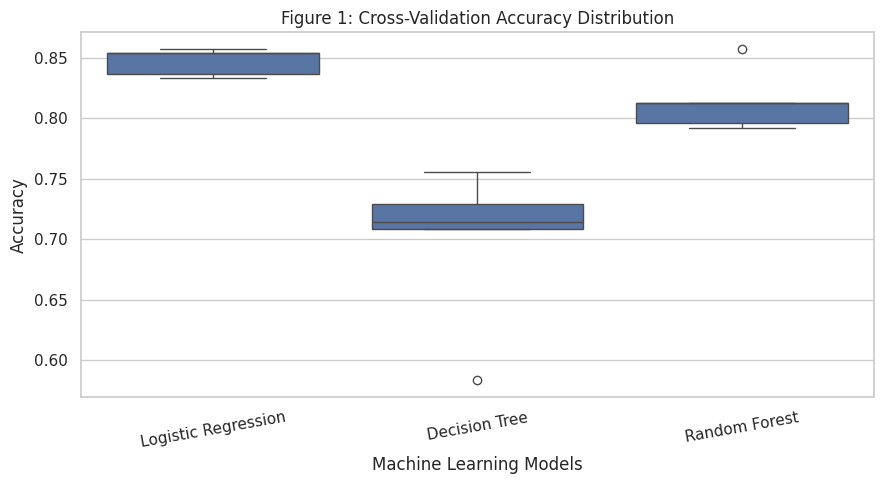


5. MODEL WITH HIGHEST MEAN ROC-AUC
----------------------------------------------------------------------
Model: Logistic Regression
Mean ROC-AUC: 0.9025
Standard Deviation: 0.0144

6. CROSS-VALIDATION VERIFICATION
----------------------------------------------------------------------
Models evaluated: 3
Folds per model: 5
Total validation scores: 15

Testing dataset used during cross-validation: No
Testing observations remain reserved: 61

STEP 8: CROSS-VALIDATION COMPLETED SUCCESSFULLY


In [21]:

# ============================================================
# STEP 8: STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate

print("=" * 70)
print("STEP 8: CROSS-VALIDATION")
print("=" * 70)

# 1. Define Stratified 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\n1. CROSS-VALIDATION CONFIGURATION")
print("-" * 70)

print("Cross-validation method: Stratified 5-Fold")
print("Number of folds:", cv.n_splits)
print("Shuffling enabled: True")
print("Random state: 42")
print("Training observations:", len(X_train))

# 2. Define evaluation metrics

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# 3. Perform cross-validation for all three models

cv_results = {}
fold_results = []

print("\n2. PERFORMING CROSS-VALIDATION")
print("-" * 70)

for model_name, pipeline in model_pipelines.items():

    print("\nEvaluating:", model_name)

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results[model_name] = scores

    # Store individual fold scores
    for fold_number in range(5):

        fold_results.append({
            "Model": model_name,
            "Fold": fold_number + 1,
            "Accuracy": scores["test_accuracy"][fold_number],
            "Precision": scores["test_precision"][fold_number],
            "Recall": scores["test_recall"][fold_number],
            "F1-score": scores["test_f1"][fold_number],
            "ROC-AUC": scores["test_roc_auc"][fold_number]
        })

    print("Cross-validation completed successfully.")


# 4. Create a table containing individual fold scores

fold_results_df = pd.DataFrame(fold_results)

print("\n3. INDIVIDUAL FOLD PERFORMANCE")
print("-" * 70)

print(
    fold_results_df.round(4).to_string(index=False)
)


# 5. Calculate mean and standard deviation for each model

summary_rows = []

for model_name, scores in cv_results.items():

    summary_rows.append({
        "Model": model_name,

        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),

        "Precision Mean": scores["test_precision"].mean(),
        "Precision Std": scores["test_precision"].std(),

        "Recall Mean": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),

        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),

        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_summary = pd.DataFrame(summary_rows)

print("\n4. CROSS-VALIDATION PERFORMANCE SUMMARY")
print("-" * 70)

print(cv_summary.round(4).to_string(index=False))


# 6. Visualize fold-wise accuracy for all models

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Figure 1: Cross-Validation Accuracy Distribution")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "step8_figure1_cross_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Display the best mean ROC-AUC model
best_model_roc_auc = cv_summary.loc[
    cv_summary["ROC-AUC Mean"].idxmax()
]

print("\n5. MODEL WITH HIGHEST MEAN ROC-AUC")
print("-" * 70)

print("Model:", best_model_roc_auc["Model"])
print("Mean ROC-AUC:", round(best_model_roc_auc["ROC-AUC Mean"], 4))
print("Standard Deviation:", round(best_model_roc_auc["ROC-AUC Std"], 4))


# 8. Final verification

print("\n6. CROSS-VALIDATION VERIFICATION")
print("-" * 70)

print("Models evaluated:", len(cv_results))
print("Folds per model:", cv.n_splits)
print("Total validation scores:", len(fold_results_df))

print("\nTesting dataset used during cross-validation: No")
print("Testing observations remain reserved:", len(X_test))

print("\nSTEP 8: CROSS-VALIDATION COMPLETED SUCCESSFULLY")

**STEP 9: MODEL EVALUATION**

STEP 9: MODEL EVALUATION

1. TRAINING AND TESTING THE MODELS
----------------------------------------------------------------------

Model: Logistic Regression
Training completed.
Testing predictions generated.

Model: Decision Tree
Training completed.
Testing predictions generated.

Model: Random Forest
Training completed.
Testing predictions generated.

2. MODEL PERFORMANCE ON TESTING DATA
----------------------------------------------------------------------
              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.8852     0.8387  0.9286    0.8814   0.9665
      Decision Tree    0.7377     0.6765  0.8214    0.7419   0.7440
      Random Forest    0.8689     0.8125  0.9286    0.8667   0.9443

3. DETAILED CLASSIFICATION REPORTS
----------------------------------------------------------------------

Classification Report: Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89     

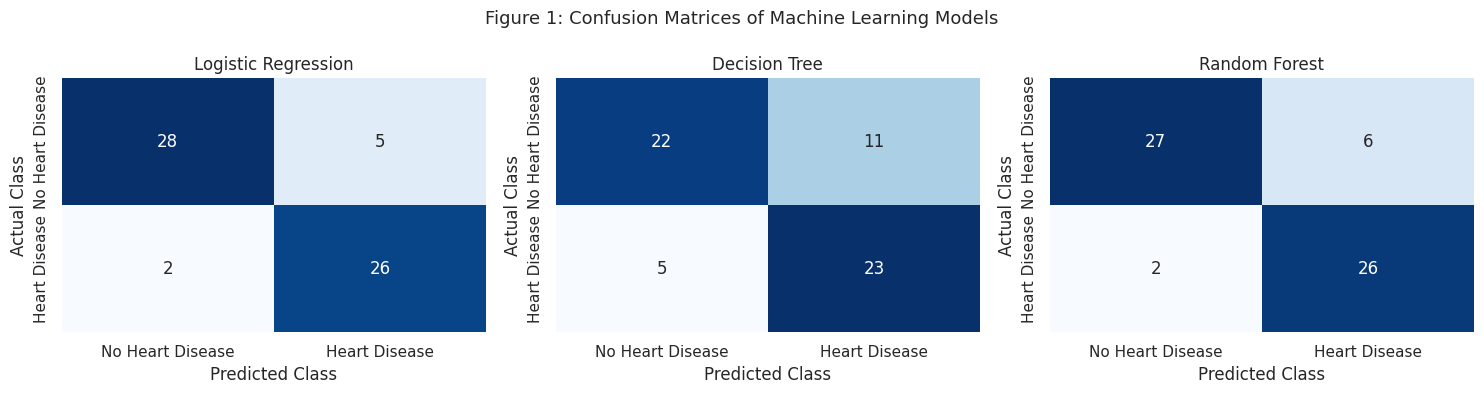

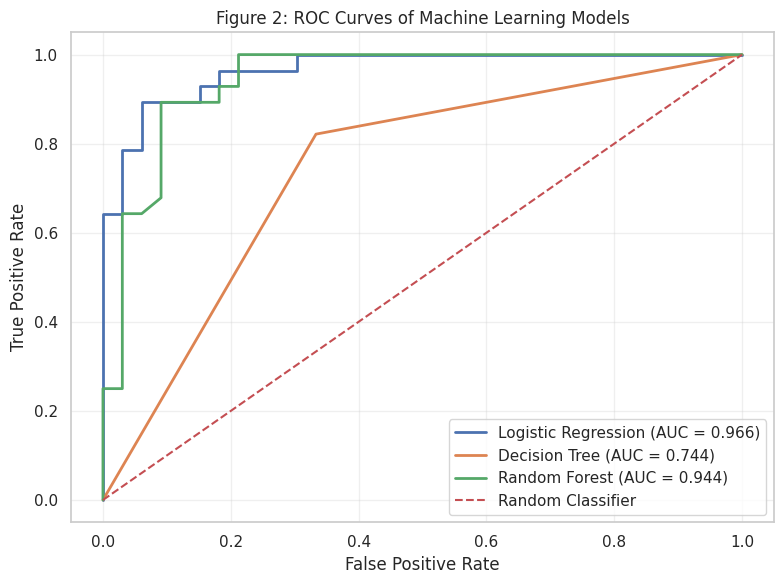

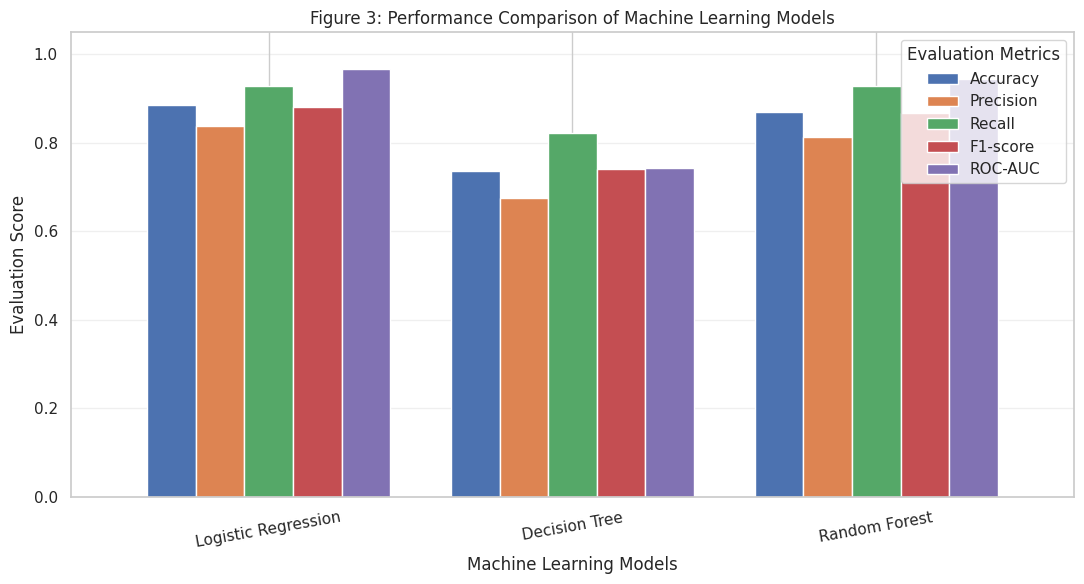


5. BEST MODEL BASED ON TEST ROC-AUC
----------------------------------------------------------------------
Model: Logistic Regression
ROC-AUC: 0.9665

6. EVALUATION VERIFICATION
----------------------------------------------------------------------
Number of models evaluated: 3
Testing observations: 61
Evaluation metrics: 5
All models trained: True
All predictions generated: True

STEP 9: MODEL EVALUATION COMPLETED SUCCESSFULLY


In [22]:
# ============================================================
# STEP 9: MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("=" * 70)
print("STEP 9: MODEL EVALUATION")
print("=" * 70)


# 1. Train and evaluate all three models

evaluation_results = []
predictions = {}
probabilities = {}
confusion_matrices = {}

print("\n1. TRAINING AND TESTING THE MODELS")
print("-" * 70)

for model_name, pipeline in model_pipelines.items():

    print("\nModel:", model_name)

    # Train the complete pipeline on training data
    pipeline.fit(X_train, y_train)

    # Predict target classes
    y_pred = pipeline.predict(X_test)

    # Predict probabilities for positive class
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Store predictions and probabilities
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    # Store confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    confusion_matrices[model_name] = cm

    # Store results
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc
    })

    print("Training completed.")
    print("Testing predictions generated.")


# 2. Display model evaluation results

evaluation_df = pd.DataFrame(evaluation_results)

print("\n2. MODEL PERFORMANCE ON TESTING DATA")
print("-" * 70)

print(evaluation_df.round(4).to_string(index=False))


# 3. Generate classification reports

print("\n3. DETAILED CLASSIFICATION REPORTS")
print("-" * 70)

for model_name, y_pred in predictions.items():

    print("\nClassification Report:", model_name)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "No Heart Disease",
                "Heart Disease"
            ],
            zero_division=0
        )
    )


# 4. Display confusion matrices

print("\n4. CONFUSION MATRICES")
print("-" * 70)

for model_name, cm in confusion_matrices.items():

    print("\n", model_name)
    print(cm)


# 5. Visualize confusion matrices

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, cm) in zip(
    axes, confusion_matrices.items()
):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=[
            "No Heart Disease",
            "Heart Disease"
        ],
        yticklabels=[
            "No Heart Disease",
            "Heart Disease"
        ],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Figure 1: Confusion Matrices of Machine Learning Models",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "step9_figure1_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 6. ROC CURVE LINE CHART

plt.figure(figsize=(8, 6))

for model_name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_value = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Figure 2: ROC Curves of Machine Learning Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step9_figure2_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Compare all evaluation metrics graphically

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

plot_data = evaluation_df.set_index("Model")[metric_columns]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Figure 3: Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=10)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step9_figure3_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 8. Identify the best model based on ROC-AUC

best_model_index = evaluation_df["ROC-AUC"].idxmax()

best_model_name = evaluation_df.loc[
    best_model_index, "Model"
]

best_model_score = evaluation_df.loc[
    best_model_index, "ROC-AUC"
]

print("\n5. BEST MODEL BASED ON TEST ROC-AUC")
print("-" * 70)

print("Model:", best_model_name)
print("ROC-AUC:", round(best_model_score, 4))


# 9. Final verification

print("\n6. EVALUATION VERIFICATION")
print("-" * 70)

print("Number of models evaluated:", len(evaluation_df))
print("Testing observations:", len(y_test))
print("Evaluation metrics:", len(metric_columns))

print("All models trained:", len(predictions) == 3)
print("All predictions generated:", len(probabilities) == 3)

print("\nSTEP 9: MODEL EVALUATION COMPLETED SUCCESSFULLY")

**STEP 10: MODEL COMPARISON**

STEP 10: MODEL COMPARISON

1. COMBINED MODEL PERFORMANCE COMPARISON
----------------------------------------------------------------------
              Model  CV Accuracy  CV Precision  CV Recall  CV F1-score  CV ROC-AUC  Test Accuracy  Test Precision  Test Recall  Test F1-score  Test ROC-AUC
Logistic Regression       0.8471        0.8768     0.7834       0.8245      0.9025         0.8852          0.8387       0.9286         0.8814        0.9665
      Decision Tree       0.6980        0.6782     0.6842       0.6768      0.6967         0.7377          0.6765       0.8214         0.7419        0.7440
      Random Forest       0.8139        0.7967     0.8008       0.7958      0.8936         0.8689          0.8125       0.9286         0.8667        0.9443

2. BEST MODEL FOR EACH TESTING METRIC
----------------------------------------------------------------------
Test Accuracy : Logistic Regression ( 0.8852 )
Test Precision : Logistic Regression ( 0.8387 )
Test Recall : Logistic Regressio

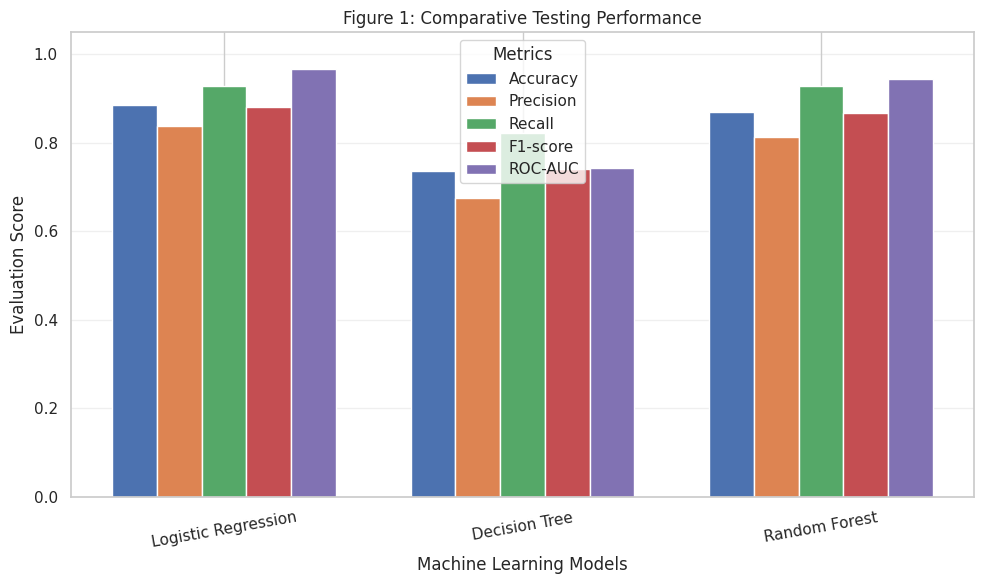

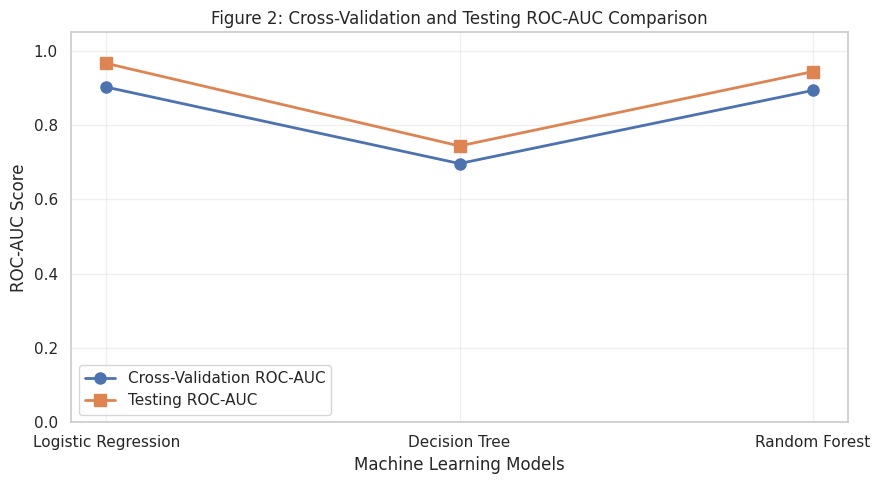


4. OVERALL MODEL COMPARISON
----------------------------------------------------------------------
Model with highest testing F1-score: Logistic Regression
Testing F1-score: 0.8814
Testing ROC-AUC: 0.9665

5. COMPARISON VERIFICATION
----------------------------------------------------------------------
Models compared: 3
Cross-validation results included: Yes
Independent testing results included: Yes

STEP 10: MODEL COMPARISON COMPLETED SUCCESSFULLY


In [23]:
# ============================================================
# STEP 10: MODEL COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("STEP 10: MODEL COMPARISON")
print("=" * 70)

# 1. Prepare cross-validation results

cv_comparison = cv_summary[
    [
        "Model",
        "Accuracy Mean",
        "Precision Mean",
        "Recall Mean",
        "F1 Mean",
        "ROC-AUC Mean"
    ]
].copy()

cv_comparison.columns = [
    "Model",
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1-score",
    "CV ROC-AUC"
]

# 2. Prepare independent testing results

test_comparison = evaluation_df.copy()

test_comparison.columns = [
    "Model",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score",
    "Test ROC-AUC"
]

# 3. Combine cross-validation and testing results

comparison_df = pd.merge(
    cv_comparison,
    test_comparison,
    on="Model"
)

print("\n1. COMBINED MODEL PERFORMANCE COMPARISON")
print("-" * 70)

print(comparison_df.round(4).to_string(index=False))


# 4. Identify the highest-performing model for each metric

print("\n2. BEST MODEL FOR EACH TESTING METRIC")
print("-" * 70)

testing_metrics = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score",
    "Test ROC-AUC"
]

for metric in testing_metrics:

    best_index = comparison_df[metric].idxmax()

    print(
        metric,
        ":",
        comparison_df.loc[best_index, "Model"],
        "(",
        round(comparison_df.loc[best_index, metric], 4),
        ")"
    )


# 5. Calculate the difference between CV and test ROC-AUC

comparison_df["ROC-AUC Difference"] = (
    comparison_df["CV ROC-AUC"] -
    comparison_df["Test ROC-AUC"]
)

print("\n3. ROC-AUC COMPARISON")
print("-" * 70)

print(
    comparison_df[
        [
            "Model",
            "CV ROC-AUC",
            "Test ROC-AUC",
            "ROC-AUC Difference"
        ]
    ].round(4).to_string(index=False)
)


# 6. Graph: Testing performance comparison

plt.figure(figsize=(10, 6))

x = np.arange(len(comparison_df))
width = 0.15

metrics = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score",
    "Test ROC-AUC"
]

for i, metric in enumerate(metrics):

    plt.bar(
        x + (i - 2) * width,
        comparison_df[metric],
        width,
        label=metric.replace("Test ", "")
    )

plt.xticks(x, comparison_df["Model"], rotation=10)
plt.ylabel("Evaluation Score")
plt.xlabel("Machine Learning Models")
plt.title("Figure 1: Comparative Testing Performance")
plt.ylim(0, 1.05)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step10_figure1_testing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Line chart: Cross-validation vs testing ROC-AUC

plt.figure(figsize=(9, 5))

plt.plot(
    comparison_df["Model"],
    comparison_df["CV ROC-AUC"],
    marker="o",
    linewidth=2,
    markersize=8,
    label="Cross-Validation ROC-AUC"
)

plt.plot(
    comparison_df["Model"],
    comparison_df["Test ROC-AUC"],
    marker="s",
    linewidth=2,
    markersize=8,
    label="Testing ROC-AUC"
)

plt.title("Figure 2: Cross-Validation and Testing ROC-AUC Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step10_figure2_cv_test_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 8. Identify the model with the highest testing F1-score

best_f1_index = comparison_df["Test F1-score"].idxmax()

best_f1_model = comparison_df.loc[
    best_f1_index, "Model"
]

print("\n4. OVERALL MODEL COMPARISON")
print("-" * 70)

print("Model with highest testing F1-score:", best_f1_model)

print(
    "Testing F1-score:",
    round(comparison_df.loc[best_f1_index, "Test F1-score"], 4)
)

print(
    "Testing ROC-AUC:",
    round(comparison_df.loc[best_f1_index, "Test ROC-AUC"], 4)
)


# 9. Final verification

print("\n5. COMPARISON VERIFICATION")
print("-" * 70)

print("Models compared:", len(comparison_df))
print("Cross-validation results included: Yes")
print("Independent testing results included: Yes")

print("\nSTEP 10: MODEL COMPARISON COMPLETED SUCCESSFULLY")

**STEP 11: FEATURE IMPORTANCE AND SHAP EXPLAINABILITY**

In [24]:
!pip install shap

STEP 11: FEATURE IMPORTANCE AND SHAP EXPLAINABILITY

1. SELECTED MODEL FOR SHAP ANALYSIS
----------------------------------------------------------------------
Selected model: Logistic Regression
Testing ROC-AUC: 0.9665

2. PERMUTATION FEATURE IMPORTANCE
----------------------------------------------------------------------

Calculating importance for: Logistic Regression

Calculating importance for: Decision Tree

Calculating importance for: Random Forest

Permutation importance calculation completed.

Feature importance: Logistic Regression
----------------------------------------------------------------------
 Feature  Importance Mean  Importance Std
      ca           0.0618          0.0229
      cp           0.0425          0.0129
 oldpeak           0.0142          0.0042
   slope           0.0119          0.0090
    thal           0.0078          0.0102
trestbps           0.0073          0.0068
     sex           0.0069          0.0071
   exang           0.0054          0.0050
 t

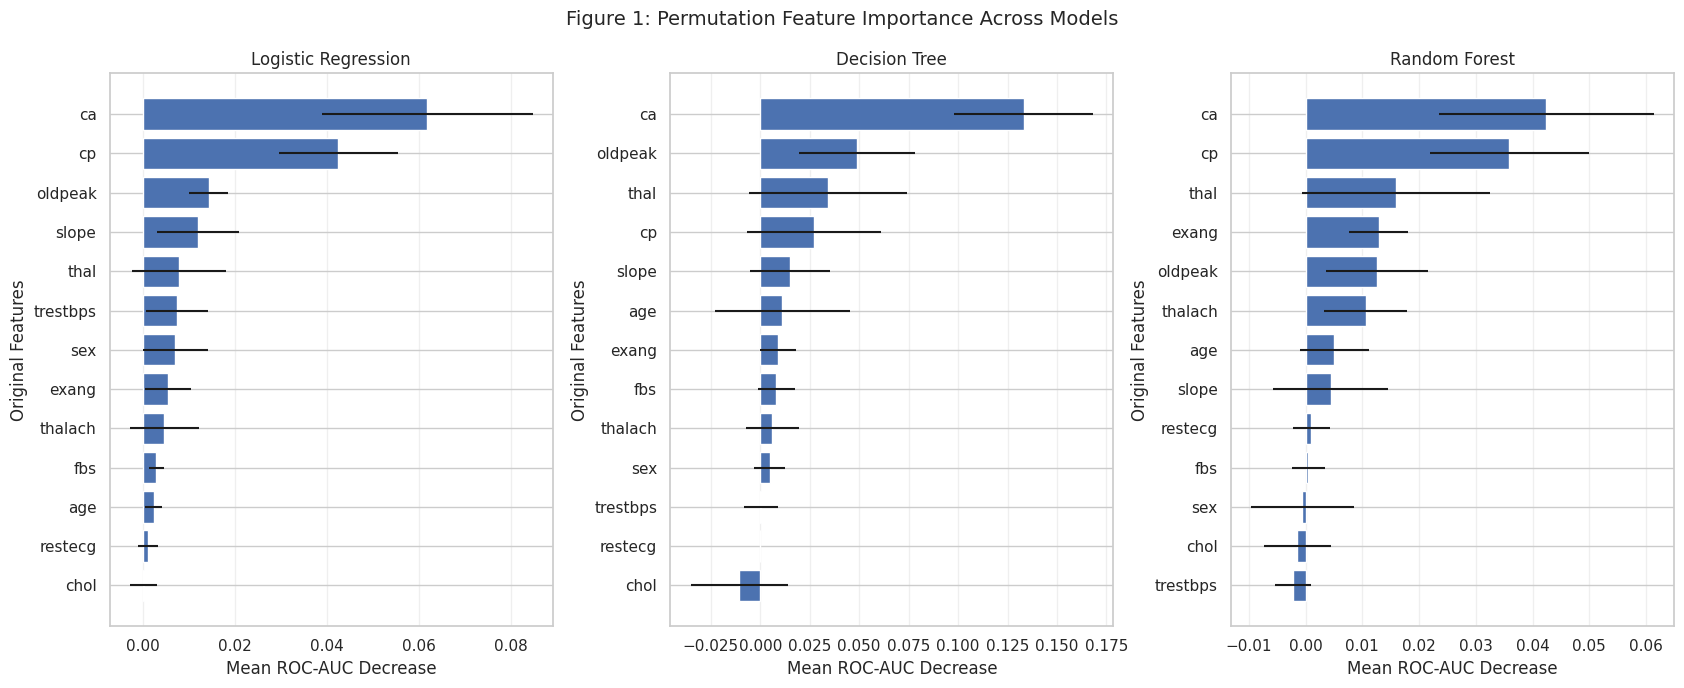


3. PREPARING DATA FOR SHAP
----------------------------------------------------------------------
Original testing features: 13
Transformed testing features: 28
Transformed data contains missing values: False

4. CALCULATING SHAP VALUES
----------------------------------------------------------------------
SHAP values calculated successfully.
SHAP values shape: (61, 28)

5. SHAP FEATURE IMPORTANCE
----------------------------------------------------------------------
       Encoded Feature  Mean Absolute SHAP
   categorical__ca_0.0              0.7442
   categorical__cp_4.0              0.5035
 categorical__thal_7.0              0.3796
   continuous__thalach              0.3160
categorical__slope_2.0              0.3012
  categorical__sex_0.0              0.2998
  categorical__sex_1.0              0.2953
 categorical__thal_3.0              0.2675
   continuous__oldpeak              0.2566
   categorical__cp_3.0              0.2553
  continuous__trestbps              0.2412
categorical

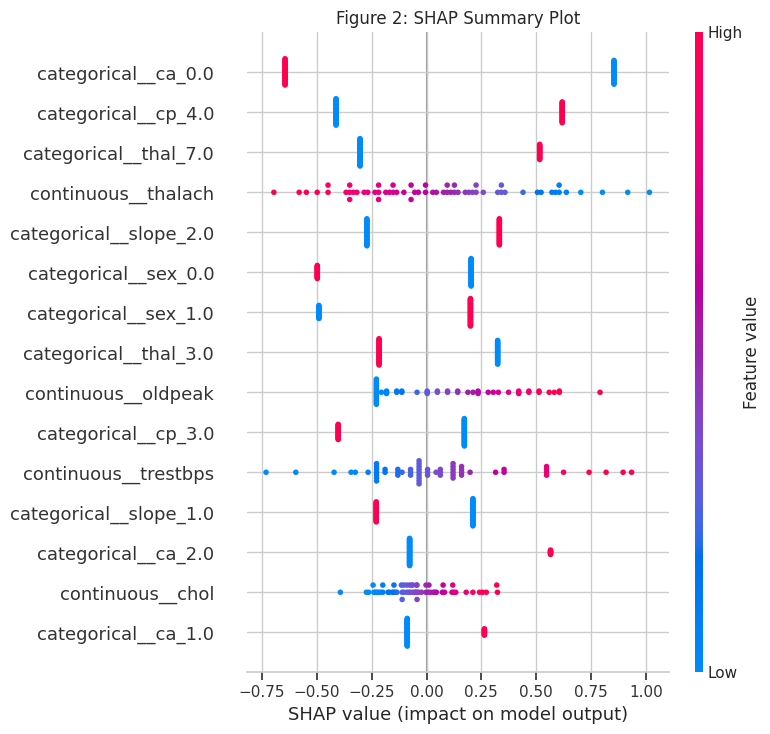

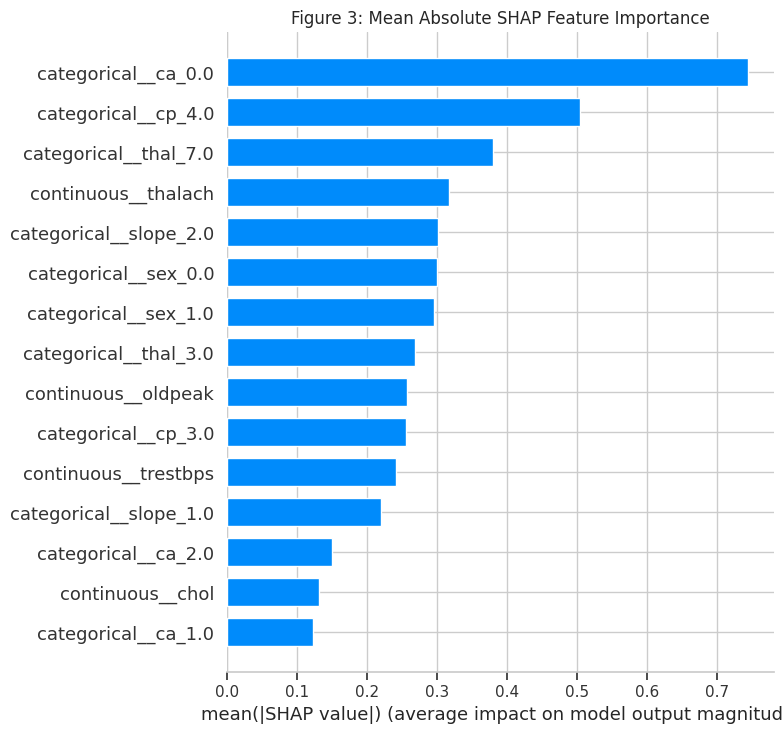


6. FEATURE IMPORTANCE SUMMARY
----------------------------------------------------------------------
Selected SHAP model: Logistic Regression

Top five permutation features for Logistic Regression:
Feature  Importance Mean
     ca           0.0618
     cp           0.0425
oldpeak           0.0142
  slope           0.0119
   thal           0.0078

Top five encoded SHAP features:
       Encoded Feature  Mean Absolute SHAP
   categorical__ca_0.0              0.7442
   categorical__cp_4.0              0.5035
 categorical__thal_7.0              0.3796
   continuous__thalach              0.3160
categorical__slope_2.0              0.3012

STEP 11: FEATURE IMPORTANCE AND SHAP COMPLETED SUCCESSFULLY


In [25]:
# ============================================================
# STEP 11: FEATURE IMPORTANCE AND SHAP EXPLAINABILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.inspection import permutation_importance

print("=" * 70)
print("STEP 11: FEATURE IMPORTANCE AND SHAP EXPLAINABILITY")
print("=" * 70)


# 1. Select the best-performing model from Step 9

best_model_name = evaluation_df.loc[
    evaluation_df["ROC-AUC"].idxmax(),
    "Model"
]

best_pipeline = model_pipelines[best_model_name]

print("\n1. SELECTED MODEL FOR SHAP ANALYSIS")
print("-" * 70)

print("Selected model:", best_model_name)
print("Testing ROC-AUC:", round(
    evaluation_df.loc[
        evaluation_df["Model"] == best_model_name,
        "ROC-AUC"
    ].iloc[0], 4
))


# 2. Calculate permutation importance for all models

print("\n2. PERMUTATION FEATURE IMPORTANCE")
print("-" * 70)

permutation_results = []

for model_name, pipeline in model_pipelines.items():

    print("\nCalculating importance for:", model_name)

    importance_result = permutation_importance(
        estimator=pipeline,
        X=X_test,
        y=y_test,
        scoring="roc_auc",
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )

    for feature, mean_importance, std_importance in zip(
        X_test.columns,
        importance_result.importances_mean,
        importance_result.importances_std
    ):

        permutation_results.append({
            "Model": model_name,
            "Feature": feature,
            "Importance Mean": mean_importance,
            "Importance Std": std_importance
        })


permutation_df = pd.DataFrame(permutation_results)

print("\nPermutation importance calculation completed.")


# 3. Display the feature importance of each model

for model_name in model_pipelines.keys():

    model_importance = permutation_df[
        permutation_df["Model"] == model_name
    ].sort_values(
        by="Importance Mean",
        ascending=False
    )

    print("\nFeature importance:", model_name)
    print("-" * 70)

    print(
        model_importance[
            ["Feature", "Importance Mean", "Importance Std"]
        ].round(4).to_string(index=False)
    )


# 4. Visualize permutation importance of all models

fig, axes = plt.subplots(1, 3, figsize=(17, 7))

for ax, model_name in zip(
    axes,
    model_pipelines.keys()
):

    model_importance = permutation_df[
        permutation_df["Model"] == model_name
    ].sort_values(
        by="Importance Mean",
        ascending=True
    )

    ax.barh(
        model_importance["Feature"],
        model_importance["Importance Mean"],
        xerr=model_importance["Importance Std"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Mean ROC-AUC Decrease")
    ax.set_ylabel("Original Features")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "Figure 1: Permutation Feature Importance Across Models",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "step11_figure1_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5. Prepare transformed data for SHAP analysis

print("\n3. PREPARING DATA FOR SHAP")
print("-" * 70)

fitted_preprocessor = best_pipeline.named_steps[
    "preprocessing"
]

fitted_classifier = best_pipeline.named_steps[
    "classifier"
]

X_test_transformed = fitted_preprocessor.transform(X_test)

encoded_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=encoded_feature_names,
    index=X_test.index
)

print("Original testing features:", X_test.shape[1])
print("Transformed testing features:", X_test_transformed_df.shape[1])

print("Transformed data contains missing values:",
      X_test_transformed_df.isnull().sum().sum() > 0)


# 6. Calculate SHAP values for Logistic Regression

print("\n4. CALCULATING SHAP VALUES")
print("-" * 70)

# Use LinearExplainer for the Logistic Regression classifier.
# The background data is sampled from the training set.

X_train_transformed = fitted_preprocessor.transform(X_train)

X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=encoded_feature_names,
    index=X_train.index
)

background_data = X_train_transformed_df.sample(
    n=min(100, len(X_train_transformed_df)),
    random_state=42
)

explainer = shap.LinearExplainer(
    fitted_classifier,
    background_data
)

shap_values = explainer(
    X_test_transformed_df
)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)


# 7. Calculate mean absolute SHAP importance

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Encoded Feature": encoded_feature_names,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

print("\n5. SHAP FEATURE IMPORTANCE")
print("-" * 70)

print(
    shap_importance_df.head(15).round(4).to_string(index=False)
)


# 8. SHAP summary plot

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    show=False,
    max_display=15
)

plt.title("Figure 2: SHAP Summary Plot")
plt.tight_layout()

plt.savefig(
    "step11_figure2_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 9. SHAP bar plot

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    plot_type="bar",
    show=False,
    max_display=15
)

plt.title("Figure 3: Mean Absolute SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "step11_figure3_shap_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 10. Final summary

print("\n6. FEATURE IMPORTANCE SUMMARY")
print("-" * 70)

print("Selected SHAP model:", best_model_name)

print("\nTop five permutation features for Logistic Regression:")

print(
    permutation_df[
        permutation_df["Model"] == best_model_name
    ].sort_values(
        by="Importance Mean",
        ascending=False
    ).head(5)[
        ["Feature", "Importance Mean"]
    ].round(4).to_string(index=False)
)

print("\nTop five encoded SHAP features:")

print(
    shap_importance_df.head(5).round(4).to_string(index=False)
)

print("\nSTEP 11: FEATURE IMPORTANCE AND SHAP COMPLETED SUCCESSFULLY")

**Step 12 – Interpretation of Model Predictions**

STEP 12: INTERPRETATION OF MODEL PREDICTIONS

1. AGGREGATING SHAP VALUES
---------------------------------------------------------------------------

SHAP IMPORTANCE AT ORIGINAL FEATURE LEVEL:
 Rank Original Feature  Mean Absolute SHAP
    1               ca            1.102460
    2               cp            0.900063
    3             thal            0.686863
    4              sex            0.595018
    5            slope            0.544582
    6          thalach            0.316028
    7          oldpeak            0.256596
    8         trestbps            0.241193
    9            exang            0.228399
   10          restecg            0.186988
   11             chol            0.130262
   12              fbs            0.057220
   13              age            0.050925

2. TOP FIVE ORIGINAL FEATURES
---------------------------------------------------------------------------
 Rank Original Feature  Mean Absolute SHAP
    1               ca            1.102460
    2       

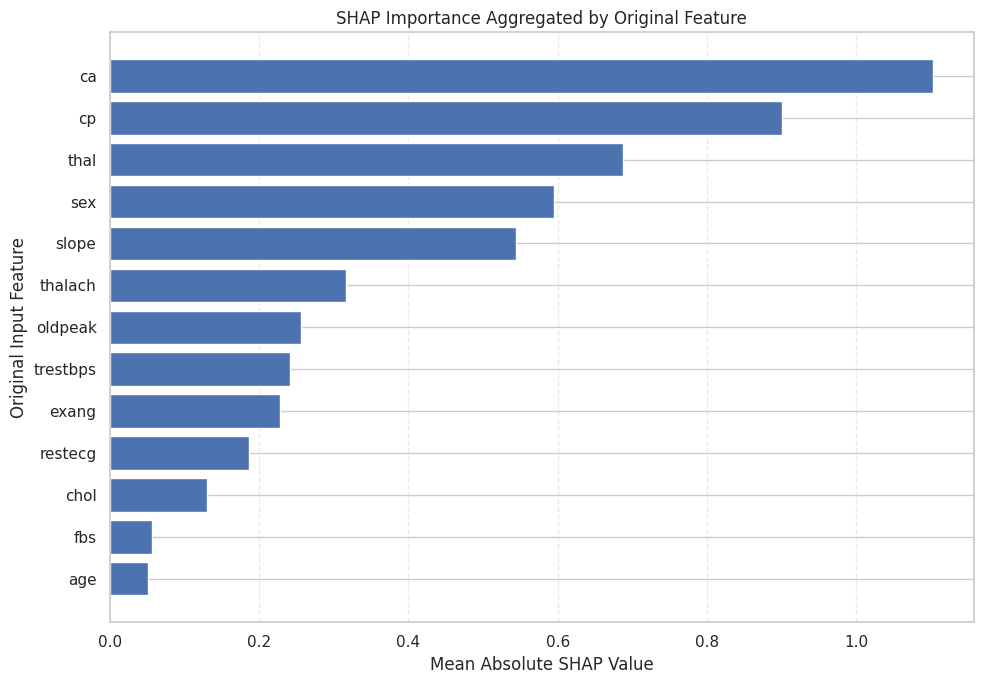


3. SELECTING AN OBSERVATION FOR LOCAL EXPLANATION
---------------------------------------------------------------------------
Selected observation index: 8
Selection method: First correctly classified positive observation
Actual class: 1
Predicted class: 1

4. SELECTED OBSERVATION'S INPUT FEATURES
---------------------------------------------------------------------------
 Feature  Observed Value
     age            35.0
     sex             1.0
      cp             4.0
trestbps           126.0
    chol           282.0
     fbs             0.0
 restecg             2.0
 thalach           156.0
   exang             1.0
 oldpeak             0.0
   slope             1.0
      ca             0.0
    thal             7.0

5. LOCAL SHAP EXPLANATION
---------------------------------------------------------------------------
The waterfall plot shows how individual encoded features contribute to this observation's model output.


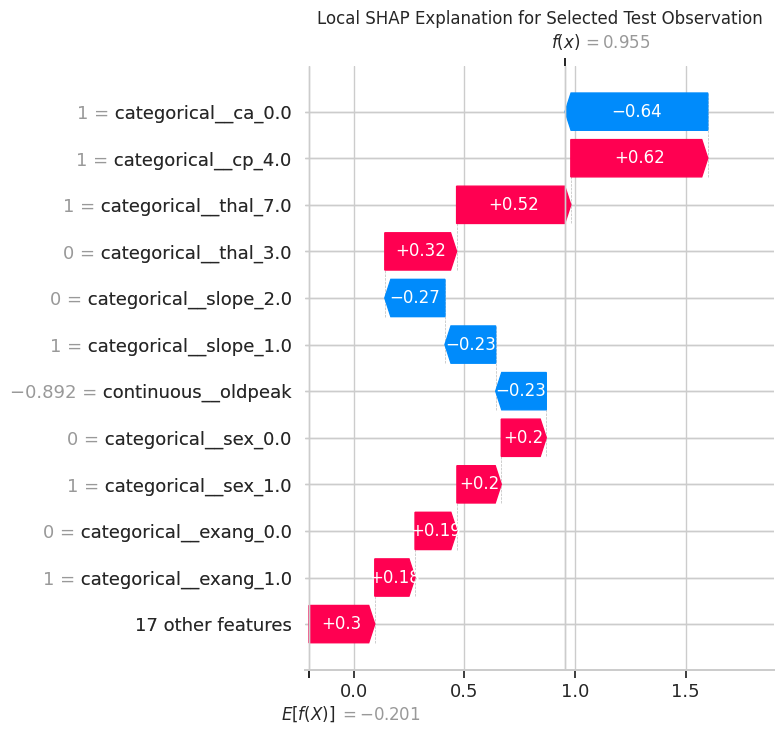


6. INTERPRETATION SUMMARY
---------------------------------------------------------------------------
Selected model: Logistic Regression

Top five original features according to aggregated SHAP:
1. ca -> 1.1025
2. cp -> 0.9001
3. thal -> 0.6869
4. sex -> 0.5950
5. slope -> 0.5446

Selected observation:
Actual class: 1
Predicted class: 1
Observation classification: Correct

STEP 12: INTERPRETATION COMPLETED SUCCESSFULLY.


In [26]:

# ======================================================================
# STEP 12: INTERPRETATION OF MODEL PREDICTIONS
# ======================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 75)
print("STEP 12: INTERPRETATION OF MODEL PREDICTIONS")
print("=" * 75)

# ----------------------------------------------------------------------
# 1. AGGREGATE SHAP VALUES INTO ORIGINAL FEATURES
# ----------------------------------------------------------------------

print("\n1. AGGREGATING SHAP VALUES")
print("-" * 75)

shap_array = shap_values.values
encoded_columns = list(X_test_transformed_df.columns)

mean_abs_shap = np.abs(shap_array).mean(axis=0)

encoded_importance_df = pd.DataFrame({
    "Encoded Feature": encoded_columns,
    "Mean Absolute SHAP": mean_abs_shap
})

original_features = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal"
]

def get_original_feature(encoded_name):

    if encoded_name.startswith("continuous__"):
        return encoded_name.replace("continuous__", "", 1)

    if encoded_name.startswith("categorical__"):
        remaining_name = encoded_name.replace("categorical__", "", 1)

        for feature in sorted(original_features, key=len, reverse=True):
            if remaining_name.startswith(feature + "_"):
                return feature

    return encoded_name

encoded_importance_df["Original Feature"] = (
    encoded_importance_df["Encoded Feature"].apply(get_original_feature)
)

# Sum absolute SHAP contributions across categories
original_importance_df = (
    encoded_importance_df
    .groupby("Original Feature")["Mean Absolute SHAP"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

original_importance_df.insert(
    0, "Rank", range(1, len(original_importance_df) + 1)
)

print("\nSHAP IMPORTANCE AT ORIGINAL FEATURE LEVEL:")
print(original_importance_df.to_string(index=False))

# ----------------------------------------------------------------------
# 2. IDENTIFY THE MOST INFLUENTIAL ORIGINAL FEATURES
# ----------------------------------------------------------------------

print("\n2. TOP FIVE ORIGINAL FEATURES")
print("-" * 75)

top_five_features = original_importance_df.head(5)

print(top_five_features.to_string(index=False))

# ----------------------------------------------------------------------
# 3. PLOT ORIGINAL FEATURE CONTRIBUTIONS
# ----------------------------------------------------------------------

plt.figure(figsize=(10, 7))

plot_df = original_importance_df.sort_values(
    "Mean Absolute SHAP", ascending=True
)

plt.barh(
    plot_df["Original Feature"],
    plot_df["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Original Input Feature")
plt.title("SHAP Importance Aggregated by Original Feature")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "step12_figure1_original_feature_interpretation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 4. SELECT ONE OBSERVATION FOR LOCAL INTERPRETATION
# ----------------------------------------------------------------------

print("\n3. SELECTING AN OBSERVATION FOR LOCAL EXPLANATION")
print("-" * 75)

actual_values = np.asarray(y_test).ravel()
predicted_values = np.asarray(best_pipeline.predict(X_test)).ravel()

# Prefer a correctly classified positive observation
candidate_indices = np.where(
    (actual_values == 1) & (predicted_values == 1)
)[0]

if len(candidate_indices) > 0:
    sample_index = int(candidate_indices[0])
    selection_reason = "First correctly classified positive observation"
else:
    sample_index = 0
    selection_reason = "First observation in the test set"

print("Selected observation index:", sample_index)
print("Selection method:", selection_reason)

actual_class = int(actual_values[sample_index])
predicted_class = int(predicted_values[sample_index])

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)

# ----------------------------------------------------------------------
# 5. DISPLAY ORIGINAL FEATURE VALUES FOR THIS OBSERVATION
# ----------------------------------------------------------------------

print("\n4. SELECTED OBSERVATION'S INPUT FEATURES")
print("-" * 75)

sample_features = X_test.iloc[sample_index]

sample_feature_df = pd.DataFrame({
    "Feature": sample_features.index,
    "Observed Value": sample_features.values
})

print(sample_feature_df.to_string(index=False))

# ----------------------------------------------------------------------
# 6. GENERATE LOCAL SHAP WATERFALL PLOT
# ----------------------------------------------------------------------

print("\n5. LOCAL SHAP EXPLANATION")
print("-" * 75)

print(
    "The waterfall plot shows how individual encoded features "
    "contribute to this observation's model output."
)

plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=12,
    show=False
)

plt.title("Local SHAP Explanation for Selected Test Observation")
plt.tight_layout()

plt.savefig(
    "step12_figure2_local_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 7. FINAL INTERPRETATION SUMMARY
# ----------------------------------------------------------------------

print("\n6. INTERPRETATION SUMMARY")
print("-" * 75)

print("Selected model: Logistic Regression")

print("\nTop five original features according to aggregated SHAP:")

for _, row in top_five_features.iterrows():
    print(
        f"{int(row['Rank'])}. {row['Original Feature']} "
        f"-> {row['Mean Absolute SHAP']:.4f}"
    )

print("\nSelected observation:")
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)

if actual_class == predicted_class:
    print("Observation classification: Correct")
else:
    print("Observation classification: Incorrect")

print("\nSTEP 12: INTERPRETATION COMPLETED SUCCESSFULLY.")


**Step 13 – Results and Discussion**

STEP 13: RESULTS AND DISCUSSION

1. FINAL MODEL PERFORMANCE ON TEST DATA
---------------------------------------------------------------------------
              Model  Accuracy  Precision   Recall  F1-score  ROC-AUC
Logistic Regression  0.885246   0.838710 0.928571  0.881356 0.966450
      Decision Tree  0.737705   0.676471 0.821429  0.741935 0.744048
      Random Forest  0.868852   0.812500 0.928571  0.866667 0.944264

2. BEST MODEL FOR EACH TEST METRIC
---------------------------------------------------------------------------
   Metric          Best Model    Score
 Accuracy Logistic Regression 0.885246
Precision Logistic Regression 0.838710
   Recall Logistic Regression 0.928571
 F1-score Logistic Regression 0.881356
  ROC-AUC Logistic Regression 0.966450

3. FIVE-FOLD CROSS-VALIDATION RESULTS
---------------------------------------------------------------------------
              Model  Accuracy Mean  Accuracy Std  Precision Mean  Precision Std  Recall Mean  Recall Std  F1-score

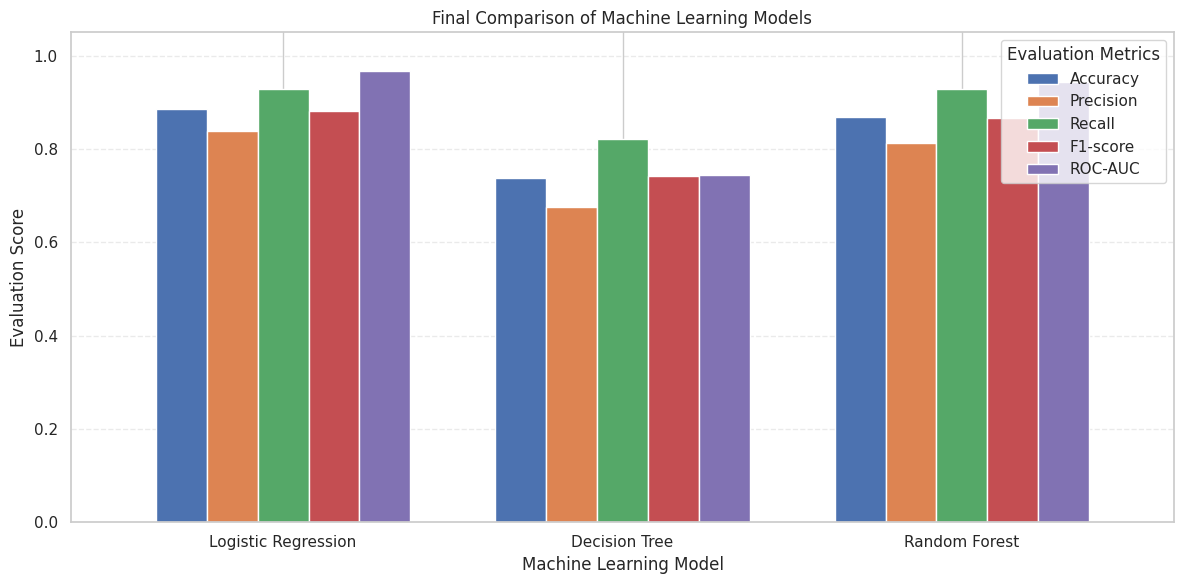


7. GENERATING CROSS-VALIDATION AND TEST ROC-AUC GRAPH
---------------------------------------------------------------------------


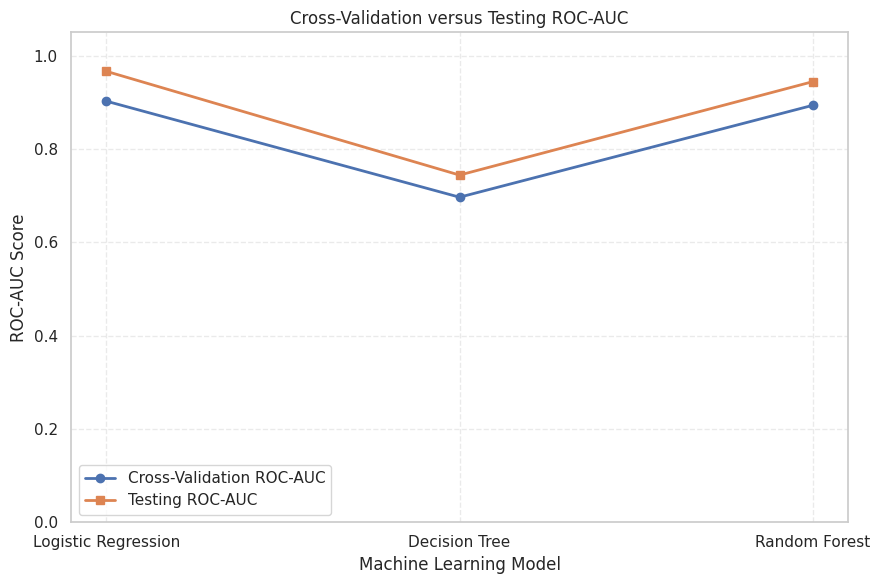


8. OVERALL BEST MODEL
---------------------------------------------------------------------------
Best model based on test ROC-AUC: Logistic Regression
Accuracy: 0.8852459016393442
Precision: 0.8387096774193549
Recall: 0.9285714285714286
F1-score: 0.8813559322033898
ROC-AUC: 0.9664502164502166

9. FINAL RESEARCH FINDINGS
---------------------------------------------------------------------------
1. Three machine-learning models were evaluated:
   Logistic Regression, Decision Tree and Random Forest.

2. Logistic Regression achieved the highest test ROC-AUC
   among the three evaluated models.

3. The feature-importance analysis identified ca and cp
   as important predictors across the models.

4. Aggregated SHAP analysis ranked ca, cp and thal
   among the most influential original features.

5. Cross-validation and independent test results were
   compared to examine model performance consistency.

10. STUDY LIMITATIONS
---------------------------------------------------------------

In [27]:

# ======================================================================
# STEP 13: RESULTS AND DISCUSSION
# ======================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 75)
print("STEP 13: RESULTS AND DISCUSSION")
print("=" * 75)

# ----------------------------------------------------------------------
# 1. FINAL TEST PERFORMANCE TABLE
# ----------------------------------------------------------------------

print("\n1. FINAL MODEL PERFORMANCE ON TEST DATA")
print("-" * 75)

final_results_df = evaluation_df.copy()

print(final_results_df.to_string(index=False))

# Identify the best model for each evaluation metric
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]

print("\n2. BEST MODEL FOR EACH TEST METRIC")
print("-" * 75)

best_metric_rows = []

for metric in metric_columns:
    if metric in final_results_df.columns:
        best_index = final_results_df[metric].astype(float).idxmax()
        best_row = final_results_df.loc[best_index]

        best_metric_rows.append({
            "Metric": metric,
            "Best Model": best_row["Model"],
            "Score": best_row[metric]
        })

best_metrics_df = pd.DataFrame(best_metric_rows)

print(best_metrics_df.to_string(index=False))

# ----------------------------------------------------------------------
# 2. CROSS-VALIDATION RESULTS
# ----------------------------------------------------------------------

print("\n3. FIVE-FOLD CROSS-VALIDATION RESULTS")
print("-" * 75)

cv_metric_map = {
    "Accuracy": "test_accuracy",
    "Precision": "test_precision",
    "Recall": "test_recall",
    "F1-score": "test_f1",
    "ROC-AUC": "test_roc_auc"
}

cv_rows = []

for model_name, result in cv_results.items():

    row = {"Model": model_name}

    for metric, key in cv_metric_map.items():

        if key in result:
            scores = np.asarray(result[key], dtype=float)
            row[metric + " Mean"] = scores.mean()
            row[metric + " Std"] = scores.std()

    cv_rows.append(row)

final_cv_df = pd.DataFrame(cv_rows)

print(final_cv_df.round(4).to_string(index=False))

# ----------------------------------------------------------------------
# 3. COMBINE CROSS-VALIDATION AND TEST ROC-AUC
# ----------------------------------------------------------------------

print("\n4. CROSS-VALIDATION VERSUS TEST ROC-AUC")
print("-" * 75)

cv_roc = final_cv_df[["Model", "ROC-AUC Mean"]].copy()

test_roc = final_results_df[["Model", "ROC-AUC"]].copy()

cv_test_comparison = pd.merge(
    cv_roc,
    test_roc,
    on="Model",
    how="inner"
)

cv_test_comparison.rename(
    columns={
        "ROC-AUC Mean": "CV ROC-AUC",
        "ROC-AUC": "Test ROC-AUC"
    },
    inplace=True
)

print(cv_test_comparison.round(4).to_string(index=False))

# ----------------------------------------------------------------------
# 4. FEATURE IMPORTANCE SUMMARY
# ----------------------------------------------------------------------

print("\n5. TOP FEATURES IDENTIFIED THROUGH SHAP")
print("-" * 75)

top_features_final = original_importance_df.head(5).copy()

print(top_features_final.to_string(index=False))

# ----------------------------------------------------------------------
# 5. FINAL PERFORMANCE COMPARISON GRAPH
# ----------------------------------------------------------------------

print("\n6. GENERATING FINAL PERFORMANCE GRAPH")
print("-" * 75)

plot_metrics = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]

available_metrics = [
    metric for metric in plot_metrics
    if metric in final_results_df.columns
]

plot_df = final_results_df.set_index("Model")[available_metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Final Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "step13_figure1_final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 6. CROSS-VALIDATION AND TEST ROC-AUC GRAPH
# ----------------------------------------------------------------------

print("\n7. GENERATING CROSS-VALIDATION AND TEST ROC-AUC GRAPH")
print("-" * 75)

plt.figure(figsize=(9, 6))

x = np.arange(len(cv_test_comparison))

plt.plot(
    x,
    cv_test_comparison["CV ROC-AUC"],
    marker="o",
    linewidth=2,
    label="Cross-Validation ROC-AUC"
)

plt.plot(
    x,
    cv_test_comparison["Test ROC-AUC"],
    marker="s",
    linewidth=2,
    label="Testing ROC-AUC"
)

plt.xticks(x, cv_test_comparison["Model"], rotation=0)
plt.xlabel("Machine Learning Model")
plt.ylabel("ROC-AUC Score")
plt.title("Cross-Validation versus Testing ROC-AUC")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "step13_figure2_cv_test_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 7. IDENTIFY OVERALL BEST MODEL
# ----------------------------------------------------------------------

print("\n8. OVERALL BEST MODEL")
print("-" * 75)

best_index = final_results_df["ROC-AUC"].astype(float).idxmax()
best_model_row = final_results_df.loc[best_index]

best_model_name = best_model_row["Model"]

print("Best model based on test ROC-AUC:", best_model_name)

for metric in metric_columns:
    if metric in final_results_df.columns:
        print(f"{metric}: {best_model_row[metric]}")

# ----------------------------------------------------------------------
# 8. FINAL RESEARCH FINDINGS
# ----------------------------------------------------------------------

print("\n9. FINAL RESEARCH FINDINGS")
print("-" * 75)

print("1. Three machine-learning models were evaluated:")
print("   Logistic Regression, Decision Tree and Random Forest.")

print("\n2. Logistic Regression achieved the highest test ROC-AUC")
print("   among the three evaluated models.")

print("\n3. The feature-importance analysis identified ca and cp")
print("   as important predictors across the models.")

print("\n4. Aggregated SHAP analysis ranked ca, cp and thal")
print("   among the most influential original features.")

print("\n5. Cross-validation and independent test results were")
print("   compared to examine model performance consistency.")

# ----------------------------------------------------------------------
# 9. LIMITATIONS
# ----------------------------------------------------------------------

print("\n10. STUDY LIMITATIONS")
print("-" * 75)

limitations = [
    "The experiment used a relatively small dataset of 303 observations.",
    "The analysis was based on the processed Cleveland subset.",
    "The test set contained only 61 observations.",
    "Model performance may vary with different data splits.",
    "Feature importance and SHAP results describe model behaviour, not causation.",
    "The models were not externally validated on an independent dataset.",
    "The experiment is not a clinical diagnostic system."
]

for number, limitation in enumerate(limitations, start=1):
    print(f"{number}. {limitation}")

# ----------------------------------------------------------------------
# 10. SAVE FINAL TABLES
# ----------------------------------------------------------------------

final_results_df.to_csv(
    "step13_final_test_results.csv",
    index=False
)

final_cv_df.to_csv(
    "step13_cross_validation_results.csv",
    index=False
)

cv_test_comparison.to_csv(
    "step13_cv_test_comparison.csv",
    index=False
)

top_features_final.to_csv(
    "step13_top_shap_features.csv",
    index=False
)

print("\n" + "=" * 75)
print("STEP 13: RESULTS AND DISCUSSION COMPLETED SUCCESSFULLY")
print("=" * 75)
